# O paradoxo da Inteligência Artificial: trabalhar com IA significa trabalhar melhor?

**Mestrado em Inteligência Artificial — Modelos Estatísticos para Inteligência Artificial (2026/2027)**
Docente: Liliana Coelho

| Aluno | Nº |
|---|---|
| Gilberto Coutinho | 3083 |
| Rúbem Mendes | 4563 |

**Questão central.** Em que medida a utilização de ferramentas de IA está associada à produtividade dos colaboradores e como se altera essa relação quando são considerados outros fatores individuais e profissionais?

**Como está organizado.** Seguimos a ordem do enunciado. Primeiro conhecemos e limpámos os dados (linhas repetidas, valores em falta, nomes de departamentos mal escritos, valores estranhos). Depois descrevemos a produtividade e o uso de IA, vimos se as duas andam juntas, comparámos os departamentos e estimámos a produtividade média. No fim construímos dois modelos de regressão: um só com o uso de IA e outro que junta a experiência, a formação em IA e a complexidade das tarefas. Comparámo-los e tirámos conclusões, separando o que é descrição, o que é inferência, o que é explicação e o que é recomendação.

**Como ler.** Cada bloco de código começa com um comentário `BLOCO x.y` que diz o que faz, porque o fazemos e como se lê o resultado. Depois de cada resultado há um texto com a nossa interpretação. Só usámos métodos dados nas aulas e nos materiais de apoio da docente.

Os dados são sintéticos (criados para o exercício): servem para treinar o raciocínio estatístico e não descrevem uma empresa real. Usámos sempre um nível de significância de 5% (α = 0,05): rejeitamos a hipótese nula quando p ≤ 0,05.

In [1]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 0.1 · Obter os dados
# O quê: garante que o ficheiro Excel existe na pasta de trabalho. No Colab descarrega-o do
# repositório GitHub; localmente usa a cópia que já está na pasta.
# Porquê: assim o notebook corre em qualquer computador ou conta Google sem configurar nada.
# ────────────────────────────────────────────────────────────────────────────────────────
import os, urllib.request, warnings
warnings.filterwarnings("ignore")

# Os dados vêm do repositório GitHub público do grupo: o notebook corre em
# qualquer conta Google (incluindo a da docente) sem montar o Drive.
URL_DADOS = ("https://raw.githubusercontent.com/gcoutinho-ipca/"
             "tp1-mepa-ia-produtividade/main/Base_Dados_IA_Produtividade.xlsx")
FICHEIRO = "Base_Dados_IA_Produtividade.xlsx"

if not os.path.exists(FICHEIRO):            # no Colab; localmente já está no clone
    urllib.request.urlretrieve(URL_DADOS, FICHEIRO)

# pasta onde se guardam as figuras usadas no relatório
PASTA_FIG = "figuras"
os.makedirs(PASTA_FIG, exist_ok=True)
print("Ficheiro de dados:", FICHEIRO, "| existe:", os.path.exists(FICHEIRO))

Ficheiro de dados: Base_Dados_IA_Produtividade.xlsx | existe: True


In [2]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 0.2 · Bibliotecas, estilo dos gráficos e funções auxiliares
# O quê: importa as bibliotecas (pandas para tabelas, scipy.stats para testes, statsmodels para
# regressões e diagnósticos), define as cores dos gráficos e funções reutilizadas:
# guardar() grava cada figura duas vezes (com a nota de leitura, para o relatório, e sem ela, para
# os diapositivos) e qq() desenha o gráfico Q-Q usado para avaliar a normalidade.
# No fim, funções para os gráficos: fpt() (números com vírgula decimal), outliers_aiq() (regra do
# box-plot), legenda_boxplot() e nota() (texto de leitura por baixo de cada figura).
# ALFA = 0,05 é o nível de significância usado em todos os testes.
# ────────────────────────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

# formato das tabelas: 3 casas decimais
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)

# Paleta legível por pessoas com daltonismo e estilo sóbrio dos gráficos
AZUL, LARANJA, AQUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CINZA_TXT, CINZA_GRELHA = "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": CINZA_TXT,
    "xtick.color": CINZA_TXT, "ytick.color": CINZA_TXT,
    "axes.grid": True, "grid.color": CINZA_GRELHA, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
})

def guardar(fig, nome):
    fig.savefig(os.path.join(PASTA_FIG, nome + ".png"))
    # versão sem a nota de leitura, para os diapositivos (onde a explicação é dita oralmente)
    if getattr(fig, "_nota", None) is not None:
        fig._nota.set_visible(False)
        fig.savefig(os.path.join(PASTA_FIG, nome + "_sem_nota.png"))
        fig._nota.set_visible(True)

def qq(serie, ax, titulo):
    # gráfico Q-Q com a reta de referência (como nas aulas: sm.qqplot com line="s")
    sm.qqplot(serie, line="s", ax=ax, marker="o", markerfacecolor=AZUL, markeredgecolor="white", markersize=4)
    ax.get_lines()[1].set(color=CINZA_TXT)
    ax.set(title=titulo, xlabel="quantis teóricos", ylabel="quantis observados")

ALFA = 0.05

# ── Funções para gráficos fáceis de ler ──────────────────────────────────────────────────────
# Convenção de cores em todos os gráficos: LARANJA só para outliers, para o limite que os define
# e para casos a assinalar; as outras linhas de referência (retas, zero, curva normal) a cinzento.
import textwrap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def fpt(x, casas=1):
    # número com vírgula decimal, como no texto em português
    return f"{x:.{casas}f}".replace(".", ",")

def outliers_aiq(serie):
    # Regra do box-plot: é outlier o valor abaixo de Q1 − 1,5×AIQ ou acima de Q3 + 1,5×AIQ
    # (AIQ = amplitude interquartil = Q3 − Q1). Devolve os outliers e os dois limites.
    q1, q3 = serie.quantile([.25, .75]); aiq = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * aiq, q3 + 1.5 * aiq
    return serie[(serie < lim_inf) | (serie > lim_sup)], lim_inf, lim_sup

def legenda_boxplot(ax, cor_linhas="black", ncol=2, y=-0.3):
    # legenda por baixo do box-plot com o significado de cada elemento
    itens = [Patch(facecolor="#cde2fb", edgecolor=AZUL, label="caixa: 50% centrais (Q1 a Q3)"),
             Line2D([], [], color=AZUL, lw=2, label="linha na caixa: mediana"),
             Line2D([], [], color=cor_linhas, lw=1, label="whiskers: até 1,5 × AIQ da caixa"),
             Line2D([], [], marker="o", ls="", markerfacecolor=LARANJA, markeredgecolor="white",
                    markersize=8, label="outlier: para lá de 1,5 × AIQ")]
    ax.legend(handles=itens, loc="upper center", bbox_to_anchor=(0.5, y), ncol=ncol,
              fontsize=7.5, frameon=False)

def nota(fig, texto):
    # nota de leitura por baixo da figura: o que cada elemento mostra e como se interpreta;
    # cada parágrafo (separado por \n) é partido em linhas à largura da figura
    largura = int(fig.get_figwidth() * 15)
    txt = "\n".join(textwrap.fill(par, largura) for par in texto.split("\n"))
    fig._nota = fig.text(0.01, 0, txt, ha="left", va="top", fontsize=8.5, color=CINZA_TXT)

---
## 1. Conhecimento e preparação da base de dados

In [3]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.0 · Ler a base de dados
# O quê: lê o Excel para uma tabela («bruto», sem alterações) e mostra as dimensões e as primeiras
# linhas. Guardamos a versão original para poder comparar com a versão limpa.
# ────────────────────────────────────────────────────────────────────────────────────────
bruto = pd.read_excel(FICHEIRO)
print(bruto.shape)
bruto.head()

(241, 11)


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
0,C001,Operações,0.500,7.700,7.700,3.000,43.700,25,1.030,81.600,68.000
1,C002,Operações,3.500,1.400,1.700,2.000,34.600,30,2.100,77.000,60.300
2,C003,Comunicação,14.000,3.300,9.200,3.000,36.800,30,3.250,85.300,89.800
3,C004,Análise de Dados,2.000,12.400,16.300,3.000,40.500,28,4.020,100.000,70.300
4,C005,Desenvolvimento,8.000,14.200,6.000,4.000,39.200,19,3.000,77.600,83.000


### 1.1. Número de registos e de colaboradores

In [4]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.1 · Registos vs colaboradores
# O quê: conta as linhas (registos) e os identificadores distintos (colaboradores).
# Leitura: 241 linhas para 240 identificadores, logo há pelo menos uma linha repetida.
# ────────────────────────────────────────────────────────────────────────────────────────
n_registos = len(bruto)
# strip() remove espaços acidentais antes de contar identificadores distintos
n_colab = bruto["id_colaborador"].str.strip().nunique()
print(f"Registos (linhas): {n_registos}")
print(f"Colaboradores distintos (id_colaborador): {n_colab}")

Registos (linhas): 241
Colaboradores distintos (id_colaborador): 240


A base tem **241 linhas**, mas só **240 códigos de colaborador diferentes** (de C001 a C240, sem falhas na numeração). Há uma linha a mais do que pessoas, por isso fomos procurar repetições.

### 1.2. Colaboradores repetidos

In [5]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.2a · Encontrar colaboradores repetidos
# O quê: mostra todas as linhas cujo identificador aparece mais do que uma vez e conta as linhas
# que são iguais em todas as colunas.
# Leitura: C084 aparece duas vezes com valores idênticos, é uma duplicação e não duas medições.
# ────────────────────────────────────────────────────────────────────────────────────────
# keep=False devolve TODAS as ocorrências do identificador repetido (não só a segunda)
rep = bruto[bruto["id_colaborador"].duplicated(keep=False)]
display(rep)
print("Linhas totalmente idênticas (todas as colunas):", bruto.duplicated().sum())

,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
83,C084,Desenvolvimento,0.500,8.500,5.700,4.000,37.800,22,5.340,64.600,61.100
198,C084,Desenvolvimento,0.500,8.500,5.700,4.000,37.800,22,5.340,64.600,61.100


Linhas totalmente idênticas (todas as colunas): 1


O colaborador **C084** aparece duas vezes (linhas 85 e 200 do Excel), com os mesmos valores em todas as colunas. É a mesma pessoa copiada duas vezes, não duas medições diferentes, e o dicionário da base confirma que cada pessoa deve aparecer uma só vez. Ficámos com a primeira linha. Se mantivéssemos as duas, o C084 contaria a dobrar nas médias, nas correlações e nas regressões.

In [6]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.2b · Remover a linha duplicada
# O quê: cria a tabela de trabalho «df» sem a cópia de C084 e confirma que cada identificador
# passa a ser único (assert falha se não for).
# Porquê: se a cópia ficasse, C084 contaria a dobrar nas médias, correlações e regressões.
# ────────────────────────────────────────────────────────────────────────────────────────
df = bruto.drop_duplicates().copy()
df["id_colaborador"] = df["id_colaborador"].str.strip()
assert df["id_colaborador"].is_unique
print("Registos após remover duplicados:", len(df))

Registos após remover duplicados: 240


### 1.3. Valores em falta

In [7]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.3 · Valores em falta
# O quê: conta os valores em falta por variável e lista os registos afetados.
# Decisão (explicada na célula seguinte): não imputar. São 8 valores em 8 registos (< 1% por
# variável); cada análise usa os registos completos nas variáveis de que precisa.
# ────────────────────────────────────────────────────────────────────────────────────────
falta = df.isna().sum()
display(falta[falta > 0].to_frame("n_em_falta"))
print("Registos com pelo menos um valor em falta:", df.isna().any(axis=1).sum())
display(df[df.isna().any(axis=1)])

,n_em_falta
experiencia_anos,1
formacao_ia_horas,1
uso_ia_horas,2
complexidade_tarefas,1
tempo_medio_tarefa_horas,1
produtividade,2


Registos com pelo menos um valor em falta: 8


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,uso_ia_horas,complexidade_tarefas,carga_trabalho_horas,tarefas_concluidas,tempo_medio_tarefa_horas,qualidade_trabalho,produtividade
29,C030,Operações,4.600,4.700,1.300,3.000,45.300,22,5.670,70.600,NaN
66,C067,Comunicação,2.300,5.100,NaN,4.000,42.600,38,2.590,78.700,89.700
79,C080,Análise de Dados,NaN,23.500,9.300,3.000,49.100,31,2.250,73.400,79.800
112,C113,Operações,9.300,10.000,NaN,3.000,42.200,41,0.400,87.000,95.000
130,C131,Operações,4.700,2.600,2.500,4.000,49.900,28,4.220,85.700,NaN
153,C154,Desenvolvimento,4.000,5.600,6.000,1.000,33.600,42,NaN,70.400,71.500
188,C189,Desenvolvimento,8.000,NaN,3.800,1.000,38.200,42,0.490,84.800,93.500
202,C202,Desenvolvimento,4.600,10.000,8.200,NaN,38.400,26,0.400,83.500,86.300


Há **8 valores em falta, cada um num registo diferente** (nenhum colaborador tem mais do que uma falha):
- `produtividade`: C030 e C131;
- `uso_ia_horas`: C067 e C113;
- `experiencia_anos`: C080; `formacao_ia_horas`: C189; `complexidade_tarefas`: C202; `tempo_medio_tarefa_horas`: C154.

**Não preenchemos os valores em falta** (não fizemos imputação). São muito poucos (menos de 1% em cada variável) e substituí-los, por exemplo pela média, seria inventar dados: diminuía a variação real e podia mexer precisamente nas relações que queremos estudar. Como nas aulas, cada análise usa os colaboradores que têm a informação de que essa análise precisa. Por isso o número de casos muda de análise para análise. Em 1.6 avaliamos se esta decisão afeta os resultados.

### 1.4. Tipos de variáveis e variável resposta

In [8]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.4 · Tipos de variáveis
# O quê: classifica cada variável (qualitativa/quantitativa) e identifica a resposta: produtividade.
# Porquê: o tipo de variável determina que gráficos e que testes podem ser usados.
# ────────────────────────────────────────────────────────────────────────────────────────
tipos = pd.DataFrame({
    "variável": df.columns,
    "tipo": ["Identificador", "Qualitativa nominal", "Quantitativa contínua", "Quantitativa contínua",
             "Quantitativa contínua", "Qualitativa ordinal (escala 1–5)", "Quantitativa contínua",
             "Quantitativa discreta", "Quantitativa contínua", "Quantitativa contínua (0–100)",
             "Quantitativa contínua (0–100) — RESPOSTA"],
})
display(tipos)

,variável,tipo
0,id_colaborador,Identificador
1,departamento,Qualitativa nominal
2,experiencia_anos,Quantitativa contínua
3,formacao_ia_horas,Quantitativa contínua
4,uso_ia_horas,Quantitativa contínua
5,complexidade_tarefas,Qualitativa ordinal (escala 1–5)
6,carga_trabalho_horas,Quantitativa contínua
7,tarefas_concluidas,Quantitativa discreta
8,tempo_medio_tarefa_horas,Quantitativa contínua
9,qualidade_trabalho,Quantitativa contínua (0–100)


In [9]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.4b · Dicionário de dados (folha «Dicionario» do Excel)
# O quê: mostra a descrição oficial de cada variável, que vem com a base de dados.
# Porquê: confirma o tipo de cada variável e diz duas coisas importantes para o resto do trabalho:
# a produtividade é uma avaliação global feita por avaliadores (NÃO é calculada a partir das outras
# colunas) e tarefas, tempo e qualidade são indicadores do mesmo desempenho.
# ────────────────────────────────────────────────────────────────────────────────────────
dicionario = pd.read_excel(FICHEIRO, sheet_name="Dicionario")
with pd.option_context("display.max_colwidth", 130):
    display(dicionario)

,Variável,Natureza / unidade,Definição e observações
0,id_colaborador,Identificador,Código anonimizado de colaborador; cada pessoa deve surgir uma vez.
1,departamento,Qualitativa nominal,Área de atividade; quatro categorias de referência.
2,experiencia_anos,Quantitativa / anos,Tempo de experiência profissional.
3,formacao_ia_horas,Quantitativa / horas,Formação acumulada em ferramentas de IA no período de referência.
4,uso_ia_horas,Quantitativa / horas/semana,Tempo médio semanal de utilização de ferramentas de IA.
5,complexidade_tarefas,Ordinal / 1–5,Complexidade média atribuída por avaliação interna.
6,carga_trabalho_horas,Quantitativa / horas/semana,Horas médias de trabalho na semana.
7,tarefas_concluidas,Contagem / tarefas,Número de tarefas concluídas no período; depende da complexidade.
8,tempo_medio_tarefa_horas,Quantitativa / horas,Tempo médio por tarefa no período.
9,qualidade_trabalho,Pontuação / 0–100,Avaliação de qualidade; indicador distinto do desempenho global.


- **Qualitativas**: `departamento` (nominal, 4 categorias) e `complexidade_tarefas` (ordinal, de 1 a 5). Nos modelos tratamos a complexidade como um número, o que supõe que a distância entre níveis é sempre a mesma. É uma simplificação; em 6.6 verificamos que não muda as conclusões.
- **Quantitativas**: experiência, formação em IA, uso de IA, carga de trabalho, tarefas concluídas, tempo médio por tarefa, qualidade e produtividade.
- `id_colaborador` serve só para identificar cada pessoa e não entra nas análises.
- A variável que queremos explicar (**variável resposta**) é a **produtividade**. A variável que nos interessa como explicação é o **uso de IA** (`uso_ia_horas`).

O dicionário da base (bloco anterior) acrescenta duas informações que usamos mais à frente: a produtividade é uma **avaliação global feita por avaliadores, não calculada a partir das outras colunas**; e tarefas concluídas, tempo por tarefa e qualidade são **indicadores do mesmo desempenho, medidos ao mesmo tempo**, pelo que é preciso cuidado ao usá-los para explicar a produtividade (ver 6.1).

### 1.5. Categorias inconsistentes e valores que merecem atenção

In [10]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.5a · Categorias do departamento (antes de limpar)
# O quê: conta os registos por departamento. Leitura: aparecem 7 grafias para 4 departamentos.
# ────────────────────────────────────────────────────────────────────────────────────────
print(df["departamento"].value_counts())

departamento
Desenvolvimento     84
Operações           65
Análise de Dados    57
Comunicação         31
desenvolvimento      1
Operacoes            1
Analise de Dados     1
Name: count, dtype: int64


In [11]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.5b · Uniformizar as categorias
# O quê: corrige as 3 grafias erradas (minúscula, falta de acentos), ficando 4 departamentos.
# Porquê: sem isto, a ANOVA trataria «Operacoes» e «Operações» como departamentos diferentes.
# ────────────────────────────────────────────────────────────────────────────────────────
uniformizar = {"desenvolvimento": "Desenvolvimento",
               "Operacoes": "Operações",
               "Analise de Dados": "Análise de Dados"}
df["departamento"] = df["departamento"].str.strip().replace(uniformizar)
print(df["departamento"].value_counts())

departamento
Desenvolvimento     85
Operações           66
Análise de Dados    58
Comunicação         31
Name: count, dtype: int64


In [12]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.5c · Valores que merecem atenção
# O quê: (1) estatísticas de todas as variáveis numéricas; (2) acumulação nos limites da escala
# (efeito de teto: 13 colaboradores com produtividade 98); (3) valores atípicos na resposta pela
# regra do box-plot (abaixo de Q1 − 1,5×AIQ: C097 e C129); (4) valores impossíveis.
# Decisão: não há valores impossíveis isolados; C097 é mantido e as análises são repetidas sem ele.
# As combinações incoerentes (tarefas × tempo face à carga) são tratadas no bloco 1.5d.
# ────────────────────────────────────────────────────────────────────────────────────────
num = df.select_dtypes("number")
display(num.describe().T[["count", "mean", "std", "min", "50%", "max"]])

# Acumulação de valores nos extremos (possíveis limites da escala)
print("produtividade = 98 (máximo):", (df.produtividade == 98).sum())
print("qualidade_trabalho = 100:", (df.qualidade_trabalho == 100).sum())
print("tempo_medio_tarefa_horas = 0,40 (mínimo):", (df.tempo_medio_tarefa_horas == 0.40).sum())
print("uso_ia_horas = 0:", (df.uso_ia_horas == 0).sum())

# Valor atípico na variável resposta: abaixo do limite inferior do box-plot (Q1 - 1,5 x AIQ)
q1, q3 = df.produtividade.quantile([.25, .75]); lim = q1 - 1.5 * (q3 - q1)
print(f"Limite inferior do box-plot (Q1 - 1,5 x AIQ): {lim:.1f}")
display(df[df.produtividade < lim][["id_colaborador", "departamento", "uso_ia_horas", "experiencia_anos",
                                    "tarefas_concluidas", "qualidade_trabalho", "produtividade"]])

# Valores impossíveis (nenhum deveria ocorrer): negativos, escalas 0-100 ultrapassadas,
# complexidade fora de 1-5 e uso de IA superior à carga de trabalho semanal
impossiveis = pd.Series({
    "valores negativos (qualquer variável numérica)": int((num < 0).sum().sum()),
    "produtividade > 100": int((df.produtividade > 100).sum()),
    "qualidade_trabalho > 100": int((df.qualidade_trabalho > 100).sum()),
    "complexidade_tarefas fora de 1–5": int((~df.complexidade_tarefas.dropna().isin([1, 2, 3, 4, 5])).sum()),
    "uso_ia_horas > carga_trabalho_horas": int((df.uso_ia_horas > df.carga_trabalho_horas).sum()),
}, name="n")
display(impossiveis.to_frame())


,count,mean,std,min,50%,max
experiencia_anos,239.000,5.846,3.984,0.300,5.000,19.000
formacao_ia_horas,239.000,9.344,7.006,0.100,7.600,36.000
uso_ia_horas,238.000,7.718,4.932,0.000,7.600,25.000
complexidade_tarefas,239.000,2.954,1.014,1.000,3.000,5.000
carga_trabalho_horas,240.000,41.895,4.324,29.200,41.900,56.000
tarefas_concluidas,240.000,30.788,7.158,12.000,30.500,49.000
tempo_medio_tarefa_horas,239.000,2.786,1.856,0.400,2.590,8.740
qualidade_trabalho,240.000,79.936,10.597,55.200,80.150,100.000
produtividade,238.000,78.034,12.837,19.000,79.350,98.000


produtividade = 98 (máximo): 13
qualidade_trabalho = 100: 9
tempo_medio_tarefa_horas = 0,40 (mínimo): 34
uso_ia_horas = 0: 11


Limite inferior do box-plot (Q1 - 1,5 x AIQ): 44.4


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,tarefas_concluidas,qualidade_trabalho,produtividade
96,C097,Desenvolvimento,7.700,7.200,34,71.100,19.000
128,C129,Comunicação,11.500,3.400,20,64.000,43.500


,n
valores negativos (qualquer variável numérica),0
produtividade > 100,0
qualidade_trabalho > 100,0
complexidade_tarefas fora de 1–5,0
uso_ia_horas > carga_trabalho_horas,0


- **Departamentos mal escritos**: `desenvolvimento` (minúscula), `Operacoes` e `Analise de Dados` (sem acentos), um registo cada. Depois de corrigidos ficam os **4 departamentos** do dicionário: Desenvolvimento (85), Operações (66), Análise de Dados (58) e Comunicação (31).
- **Valores impossíveis**: não há valores impossíveis isolados (nenhum negativo, nenhuma produtividade acima de 100, ninguém com mais horas de IA do que de trabalho). Há, no entanto, **combinações incoerentes** entre tarefas, tempo por tarefa e carga de trabalho, tratadas no bloco 1.5d a seguir.
- **Acumulação nos limites**: 13 colaboradores têm produtividade exatamente 98, que é também o máximo; 34 têm o tempo mínimo por tarefa (0,40 h) e 9 têm qualidade 100. Parece que a escala tem um «teto»: a partir de certo ponto não conseguimos distinguir os melhores uns dos outros. Fica como limitação.
- **C097** tem produtividade 19, muito abaixo do valor seguinte (43,5), e isso não bate certo com os outros dados dele (34 tarefas concluídas e qualidade 71,1, ambos perto da média). Pode ser um erro de registo, mas não o conseguimos provar e o valor está dentro da escala. Como se aprende nas aulas, um valor estranho investiga-se, não se elimina automaticamente: mantivemos o C097 e repetimos as análises principais sem ele, para ver se alguma conclusão muda. O C129 (43,5) também é baixo, mas plausível.
- **11 colaboradores não usam IA** (0 h). É um valor possível e foi mantido.

,n incoerentes
1 semana,174
2 semanas,109
4 semanas,15
"1 mês (4,33 semanas)",10


Marcados (mais de 4.33 semanas de trabalho): 10


,id_colaborador,departamento,tarefas_concluidas,tempo_medio_tarefa_horas,carga_trabalho_horas,horas_tarefas,semanas_necessarias,produtividade
68,C069,Operações,35,8.740,41.200,305.900,7.425,81.000
110,C111,Desenvolvimento,31,6.730,38.600,208.630,5.405,64.800
194,C195,Operações,39,3.670,29.200,143.130,4.902,61.000
174,C175,Desenvolvimento,39,5.450,44.400,212.550,4.787,64.700
173,C174,Desenvolvimento,31,6.380,41.400,197.780,4.777,64.100
155,C156,Desenvolvimento,31,6.080,40.900,188.480,4.608,66.700
30,C031,Comunicação,29,5.640,36.500,163.560,4.481,66.200
85,C086,Desenvolvimento,32,5.970,43.200,191.040,4.422,55.500
95,C096,Desenvolvimento,31,5.680,40.100,176.080,4.391,80.700
233,C233,Operações,34,5.450,42.700,185.300,4.340,66.500


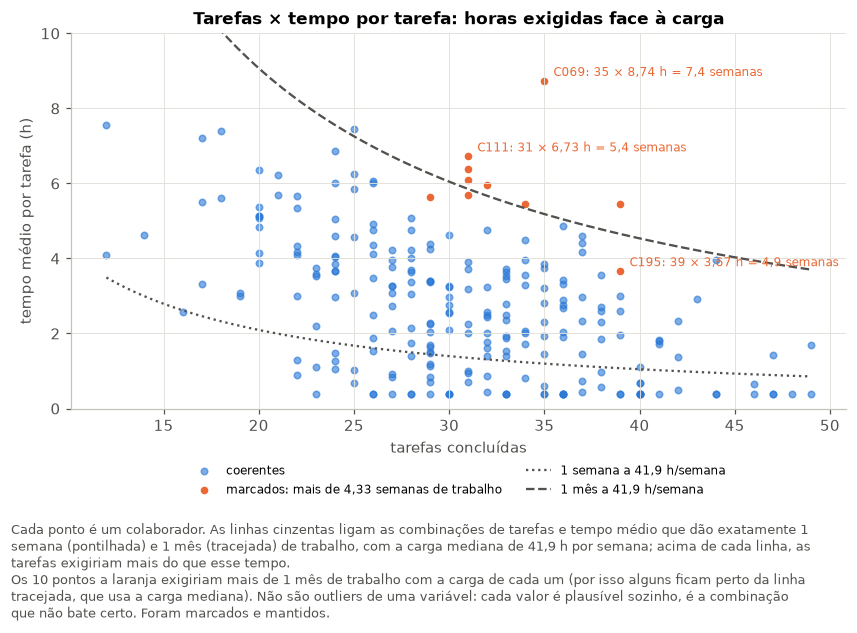

In [13]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.5d · Coerência entre tarefas, tempo por tarefa e carga de trabalho
# O quê: cada valor isolado é plausível, mas a combinação pode não ser. Horas exigidas pelas
# tarefas = tarefas_concluidas × tempo_medio_tarefa_horas; dividindo pela carga semanal obtém-se
# o número de semanas de trabalho que essas tarefas exigiriam.
# Porquê vários limites: o dicionário não define a duração do «período» das tarefas, só que é
# comum a todos; a carga é semanal. Mostra-se quantos casos ficam incoerentes com cada período.
# Decisão: marcar (não apagar nem imputar) quem precisaria de mais de 1 mês (4,33 semanas) de
# trabalho; a correlação (3.2) e a ANOVA (4.4a) são repetidas sem estes casos.
# ────────────────────────────────────────────────────────────────────────────────────────
df["horas_tarefas"] = df.tarefas_concluidas * df.tempo_medio_tarefa_horas
df["semanas_necessarias"] = df.horas_tarefas / df.carga_trabalho_horas

# Sensibilidade ao período assumido (C154 não tem tempo por tarefa e fica de fora da contagem)
limites = {"1 semana": 1, "2 semanas": 2, "4 semanas": 4, "1 mês (4,33 semanas)": 4.33}
display(pd.Series({k: int((df.semanas_necessarias > v).sum()) for k, v in limites.items()},
                  name="n incoerentes").to_frame())

LIMITE_SEMANAS = 4.33   # período assumido: 1 mês
df["flag_incoerente"] = df.semanas_necessarias > LIMITE_SEMANAS
INCOERENTES = df.loc[df.flag_incoerente, "id_colaborador"].tolist()
print(f"Marcados (mais de {LIMITE_SEMANAS} semanas de trabalho): {len(INCOERENTES)}")
display(df.loc[df.flag_incoerente, ["id_colaborador", "departamento", "tarefas_concluidas",
                                    "tempo_medio_tarefa_horas", "carga_trabalho_horas", "horas_tarefas",
                                    "semanas_necessarias", "produtividade"]]
        .sort_values("semanas_necessarias", ascending=False))

# Gráfico: tarefas × tempo por tarefa, com as isolinhas de 1 semana e de 1 mês à carga mediana
fig, ax = plt.subplots(figsize=(8, 4.8))
ok = df[~df.flag_incoerente]; mau = df[df.flag_incoerente]
ax.scatter(ok.tarefas_concluidas, ok.tempo_medio_tarefa_horas, color=AZUL, alpha=0.6, s=18, label="coerentes")
ax.scatter(mau.tarefas_concluidas, mau.tempo_medio_tarefa_horas, color=LARANJA, s=36, edgecolor="white",
           label=f"marcados: mais de {fpt(LIMITE_SEMANAS, 2)} semanas de trabalho")
x = np.linspace(df.tarefas_concluidas.min(), df.tarefas_concluidas.max(), 100)
carga = df.carga_trabalho_horas.median()
for sem, estilo, nome in [(1, ":", "1 semana"), (LIMITE_SEMANAS, "--", "1 mês")]:
    ax.plot(x, sem * carga / x, color=CINZA_TXT, linestyle=estilo, label=f"{nome} a {fpt(carga)} h/semana")
# os três casos mais extremos, com a conta que os torna incoerentes
for _, r in mau.nlargest(3, "semanas_necessarias").iterrows():
    ax.annotate(f"{r.id_colaborador}: {r.tarefas_concluidas} × {fpt(r.tempo_medio_tarefa_horas, 2)} h = "
                f"{fpt(r.semanas_necessarias)} semanas", (r.tarefas_concluidas, r.tempo_medio_tarefa_horas),
                xytext=(6, 3), textcoords="offset points", fontsize=8, color=LARANJA)
ax.set(xlabel="tarefas concluídas", ylabel="tempo médio por tarefa (h)", ylim=(0, 10),
       title="Tarefas × tempo por tarefa: horas exigidas face à carga")
ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
nota(fig, f"Cada ponto é um colaborador. As linhas cinzentas ligam as combinações de tarefas e tempo médio que dão "
          f"exatamente 1 semana (pontilhada) e 1 mês (tracejada) de trabalho, com a carga mediana de {fpt(carga)} h por "
          f"semana; acima de cada linha, as tarefas exigiriam mais do que esse tempo.\n"
          f"Os {len(mau)} pontos a laranja exigiriam mais de 1 mês de trabalho com a carga de cada um (por isso alguns ficam "
          f"perto da linha tracejada, que usa a carga mediana). Não são outliers de uma variável: cada valor é plausível "
          f"sozinho, é a combinação que não bate certo. Foram marcados e mantidos.")
guardar(fig, "fig_1_5d_coerencia_tarefas")
plt.show()

**Coerência entre tarefas, tempo e carga.** Nenhum destes valores é impossível sozinho, mas alguns colaboradores combinam muitas tarefas com um tempo médio alto. O caso mais extremo é o **C069**: 35 tarefas × 8,74 h = 306 h, com 41,2 h de trabalho por semana, o que daria cerca de 7,4 semanas de trabalho a tempo inteiro.

O dicionário não diz quanto dura o «período» das tarefas, por isso não há um limite único. Com um período de uma semana, a maioria dos colaboradores ficaria incoerente, o que mostra que o período tem de ser mais longo. Com um período de um mês (4,33 semanas), ficam **10 colaboradores** acima do limite (tabela acima).

Há duas explicações possíveis, e nenhuma se consegue provar com estes dados:
- os dados são sintéticos (o dicionário diz «Dados inteiramente sintéticos»), e as colunas parecem ter sido geradas sem esta restrição;
- o «tempo médio por tarefa» pode medir a duração da tarefa e não o esforço: com várias tarefas em paralelo, 8 h de duração não são 8 h de trabalho.

**Decisão.** Seguimos o mesmo critério do C097: os casos foram **marcados e mantidos**, sem apagar nem imputar valores, e a correlação (3.2) e a ANOVA (4.4a) são repetidas sem eles. Tarefas concluídas e tempo por tarefa não entram nos modelos de regressão (ver 6.1), por isso esta incoerência não afeta as regressões. Sem os 10 casos, a correlação de Pearson fica igual (r = 0,24) e a ANOVA passa de p = 0,70 para p = 0,56: nenhuma conclusão muda.

### 1.6. Colaboradores disponíveis para análise

In [14]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.6 · Quantos casos entram em cada análise
# O quê: conta os colaboradores com informação completa nas variáveis de cada capítulo.
# Leitura: 240 na base limpa, 238 com produtividade, 236 com IA e produtividade, 233 no modelo
# múltiplo. O n varia porque não imputámos valores em falta.
# ────────────────────────────────────────────────────────────────────────────────────────
conjuntos = {
    "Base limpa (colaboradores únicos)": df,
    "Com produtividade (cap. 2 e 4)": df.dropna(subset=["produtividade"]),
    "Com uso de IA": df.dropna(subset=["uso_ia_horas"]),
    "Com uso de IA e produtividade (cap. 3 e 5)": df.dropna(subset=["uso_ia_horas", "produtividade"]),
    "Modelo múltiplo (cap. 6)": df.dropna(subset=["produtividade", "uso_ia_horas", "experiencia_anos",
                                                  "formacao_ia_horas", "complexidade_tarefas"]),
}
display(pd.Series({k: len(v) for k, v in conjuntos.items()}, name="n").to_frame())

,n
Base limpa (colaboradores únicos),240
Com produtividade (cap. 2 e 4),238
Com uso de IA,238
Com uso de IA e produtividade (cap. 3 e 5),236
Modelo múltiplo (cap. 6),233


In [15]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 1.6b · Faz sentido deixar de fora os registos com falhas?
# O quê: para cada um dos 8 registos com um valor em falta, mostra a variável que falta, de que
# análises sai e compara-os com os restantes; no fim compara a correlação IA–produtividade com
# 236 e com 233 casos.
# Porquê: deixar casos de fora só é aceitável se forem poucos e se a sua saída não mudar os
# resultados.
# ────────────────────────────────────────────────────────────────────────────────────────
sai_de = {"produtividade": "todas as análises da produtividade (é a variável resposta)",
          "uso_ia_horas": "correlação e regressões (é a variável de interesse)",
          "experiencia_anos": "só a regressão múltipla",
          "formacao_ia_horas": "só a regressão múltipla",
          "complexidade_tarefas": "só a regressão múltipla",
          "tempo_medio_tarefa_horas": "nenhuma (variável não usada nos modelos)"}
incompletos = df[df.isna().any(axis=1)].copy()
# cada registo tem uma só falha: guardamos o nome da coluna em falta
incompletos["falta"] = incompletos.apply(lambda linha: linha.index[linha.isna()][0], axis=1)
incompletos["sai_de"] = incompletos["falta"].map(sai_de)
display(incompletos[["id_colaborador", "departamento", "falta", "uso_ia_horas", "experiencia_anos",
                     "produtividade", "sai_de"]])

completos = df.dropna()
print(f"Produtividade média: registos completos = {completos.produtividade.mean():.1f} | "
      f"incompletos = {incompletos.produtividade.mean():.1f} (n = {incompletos.produtividade.notna().sum()})")
d_236 = conjuntos["Com uso de IA e produtividade (cap. 3 e 5)"]
d_233 = conjuntos["Modelo múltiplo (cap. 6)"]
print(f"Correlação IA–produtividade com 236 casos: r = {st.pearsonr(d_236.uso_ia_horas, d_236.produtividade).statistic:.3f}")
print(f"Correlação IA–produtividade com 233 casos: r = {st.pearsonr(d_233.uso_ia_horas, d_233.produtividade).statistic:.3f}")

,id_colaborador,departamento,falta,uso_ia_horas,experiencia_anos,produtividade,sai_de
29,C030,Operações,produtividade,1.300,4.600,NaN,todas as análises da produtividade (é a variáv...
66,C067,Comunicação,uso_ia_horas,NaN,2.300,89.700,correlação e regressões (é a variável de inter...
79,C080,Análise de Dados,experiencia_anos,9.300,NaN,79.800,só a regressão múltipla
112,C113,Operações,uso_ia_horas,NaN,9.300,95.000,correlação e regressões (é a variável de inter...
130,C131,Operações,produtividade,2.500,4.700,NaN,todas as análises da produtividade (é a variáv...
153,C154,Desenvolvimento,tempo_medio_tarefa_horas,6.000,4.000,71.500,nenhuma (variável não usada nos modelos)
188,C189,Desenvolvimento,formacao_ia_horas,3.800,8.000,93.500,só a regressão múltipla
202,C202,Desenvolvimento,complexidade_tarefas,8.200,4.600,86.300,só a regressão múltipla


Produtividade média: registos completos = 77.8 | incompletos = 86.0 (n = 6)
Correlação IA–produtividade com 236 casos: r = 0.241
Correlação IA–produtividade com 233 casos: r = 0.246


**Faz sentido deixar estes registos de fora?** Sim, e a tabela mostra porquê:
- **C154** só não tem o tempo médio por tarefa, uma variável que não usamos nos modelos. Entra em todas as análises.
- **C080, C189 e C202** só saem da regressão múltipla, porque lhes falta uma das variáveis do modelo. Entram em tudo o resto.
- **C067 e C113** não têm uso de IA, a variável que estamos a estudar. Não há forma honesta de os pôr na correlação ou nas regressões sem inventar esse valor. Entram na descrição da produtividade e na comparação entre departamentos.
- **C030 e C131** não têm produtividade, que é precisamente o que queremos explicar. Preencher a resposta seria inventar o resultado. Entram só na descrição do uso de IA.

Os 6 registos incompletos com produtividade conhecida têm, em média, uma produtividade um pouco mais alta (86,0 contra 77,8), mas são só 6 em 240 e cada um sai apenas das análises a que lhe falta informação. O que interessa é saber se a saída destes casos muda os resultados: a correlação entre IA e produtividade é praticamente a mesma com 236 casos (r = 0,241) e com os 233 do modelo múltiplo (r = 0,246). Também não faz sentido retirar nenhuma variável do estudo por causa das faltas: em nenhuma faltam mais de 2 valores.

Ficam **240 colaboradores**: só retirámos a linha repetida do C084, e nenhuma pessoa foi excluída por inteiro. O número de casos depende das variáveis de cada análise: 238 com produtividade, 236 com uso de IA e produtividade, e 233 com todas as variáveis do modelo múltiplo. Para comparar os dois modelos de regressão de forma justa (6.5), voltámos a estimar o modelo simples com os mesmos 233 casos.

---
## 2. Caracterização dos colaboradores

### 2.1. Produtividade média

In [16]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 2.1 · Produtividade média
# O quê: média, mediana, desvio-padrão, quartis e amplitude interquartil (AIQ) da produtividade.
# Leitura: média (78,0) perto da mediana (79,35), logo a média representa razoavelmente os dados;
# fica um pouco abaixo por causa de alguns valores muito baixos.
# ────────────────────────────────────────────────────────────────────────────────────────
p = df["produtividade"].dropna()
resumo_p = pd.Series({
    "n": len(p), "média": p.mean(), "mediana": p.median(), "desvio-padrão": p.std(),
    "mínimo": p.min(), "Q1": p.quantile(.25), "Q3": p.quantile(.75), "máximo": p.max(),
    "AIQ": p.quantile(.75) - p.quantile(.25),
})
resumo_p.round(2).to_frame("produtividade")

,produtividade
n,238.000
média,78.030
mediana,79.350
desvio-padrão,12.840
mínimo,19.000
Q1,70.220
Q3,87.450
máximo,98.000
AIQ,17.230


A produtividade média é **78,0 pontos** (desvio-padrão 12,8; n = 238). A média representa bem os dados: está perto da mediana (79,35) e metade dos colaboradores tem entre 70,2 e 87,5 pontos. Fica um pouco abaixo da mediana porque alguns valores muito baixos (C097 = 19; C129 = 43,5) a puxam para baixo. Para descrever o colaborador típico, a mediana é um pouco mais segura, porque não é afetada por esses casos.

### 2.2. Utilização semanal de IA

Média = 7.72 h | mediana = 7.60 h | dp = 4.93 h | mín = 0.0 | máx = 25.0 | n = 238
Limite superior do box-plot (Q3 + 1,5·AIQ) = 21.20 h


,id_colaborador,departamento,uso_ia_horas,formacao_ia_horas,produtividade
34,C035,Comunicação,24.800,6.100,82.100
133,C134,Desenvolvimento,25.000,36.000,71.600


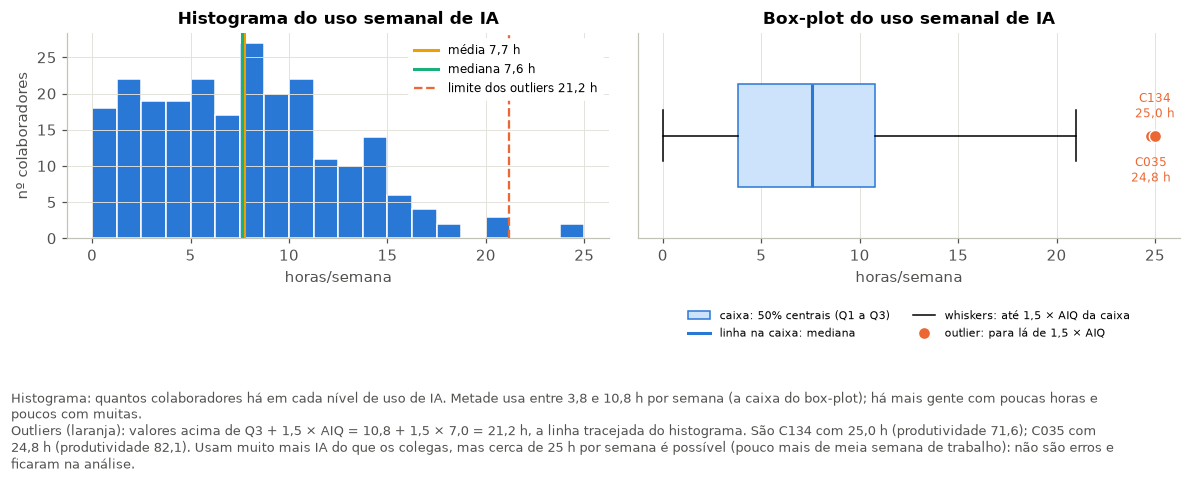

In [17]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 2.2 · Uso semanal de IA e valores extremos
# O quê: média e dispersão do uso de IA; identifica quem está acima do limite superior do box-plot
# (Q3 + 1,5×AIQ = 21,2 h) e desenha histograma e box-plot (Figura 1 do relatório).
# Leitura: C134 (25 h) e C035 (24,8 h) são extremos, mas plausíveis, por isso ficam.
# ────────────────────────────────────────────────────────────────────────────────────────
u = df["uso_ia_horas"].dropna()
# regra do box-plot para identificar valores muito superiores aos restantes
q1, q3 = u.quantile([.25, .75]); lim_sup = q3 + 1.5 * (q3 - q1)
print(f"Média = {u.mean():.2f} h | mediana = {u.median():.2f} h | dp = {u.std():.2f} h | "
      f"mín = {u.min()} | máx = {u.max()} | n = {len(u)}")
print(f"Limite superior do box-plot (Q3 + 1,5·AIQ) = {lim_sup:.2f} h")
display(df[df.uso_ia_horas > lim_sup][["id_colaborador", "departamento", "uso_ia_horas", "formacao_ia_horas", "produtividade"]])

fora = df[df.uso_ia_horas > lim_sup].sort_values("uso_ia_horas", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(u, bins=20, color=AZUL, edgecolor="white")
ax[0].axvline(u.mean(), color=AMARELO, lw=2, label=f"média {fpt(u.mean())} h")
ax[0].axvline(u.median(), color=AQUA, lw=2, label=f"mediana {fpt(u.median())} h")
ax[0].axvline(lim_sup, color=LARANJA, lw=1.5, ls="--", label=f"limite dos outliers {fpt(lim_sup)} h")
ax[0].legend(fontsize=8, frameon=True, facecolor="white", edgecolor="white", framealpha=1)
ax[0].set(title="Histograma do uso semanal de IA", xlabel="horas/semana", ylabel="nº colaboradores")
ax[1].boxplot(u, vert=False, widths=.5, patch_artist=True,
              boxprops=dict(facecolor="#cde2fb", color=AZUL), medianprops=dict(color=AZUL, lw=2),
              flierprops=dict(marker="o", markerfacecolor=LARANJA, markeredgecolor="white", markersize=8))
# código e valor de cada outlier, alternando acima e abaixo do ponto para não se sobreporem
for k, (_, r) in enumerate(fora.iterrows()):
    ax[1].annotate(f"{r.id_colaborador}\n{fpt(r.uso_ia_horas)} h", (r.uso_ia_horas, 1),
                   xytext=(0, 12 if k % 2 == 0 else -30), textcoords="offset points",
                   ha="center", fontsize=8, color=LARANJA)
ax[1].set(title="Box-plot do uso semanal de IA", xlabel="horas/semana", yticks=[])
legenda_boxplot(ax[1])
plt.tight_layout()
lista = "; ".join(f"{r.id_colaborador} com {fpt(r.uso_ia_horas)} h (produtividade {fpt(r.produtividade)})"
                  for _, r in fora.iterrows())
nota(fig, f"Histograma: quantos colaboradores há em cada nível de uso de IA. Metade usa entre {fpt(q1)} e {fpt(q3)} h por "
          f"semana (a caixa do box-plot); há mais gente com poucas horas e poucos com muitas.\n"
          f"Outliers (laranja): valores acima de Q3 + 1,5 × AIQ = {fpt(q3)} + 1,5 × {fpt(q3 - q1)} = {fpt(lim_sup)} h, "
          f"a linha tracejada do histograma. São {lista}. Usam muito mais IA do que os colegas, mas cerca de 25 h por "
          f"semana é possível (pouco mais de meia semana de trabalho): não são erros e ficaram na análise.")
guardar(fig, "fig_2_2_uso_ia"); plt.show()

Em média, os colaboradores usam IA **7,7 horas por semana** (mediana 7,6 h; desvio-padrão 4,9 h; n = 238). O histograma mostra mais gente com poucas horas e alguns com muitas (cauda à direita). Dois colaboradores ficam acima do limite superior do box-plot (21,2 h), assinalados a laranja como outliers: **C134 (25,0 h)** e **C035 (24,8 h)**. São valores possíveis (pouco mais de meia semana de 40 h), por isso ficam. Vamos, no entanto, ver se pesam demasiado nos modelos.

### 2.3. Produtividade e uso de IA por departamento

In [18]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 2.3 · Produtividade e uso de IA por departamento
# O quê: tabela por departamento (n, média, mediana e desvio-padrão da produtividade; média e
# mediana do uso de IA), ordenada pela produtividade média.
# Leitura: Operações é o mais produtivo; Desenvolvimento é o que mais usa IA. Não coincidem.
# ────────────────────────────────────────────────────────────────────────────────────────
por_dep = (df.groupby("departamento")
             .agg(n=("produtividade", "count"),
                  prod_media=("produtividade", "mean"), prod_mediana=("produtividade", "median"),
                  prod_dp=("produtividade", "std"),
                  ia_media=("uso_ia_horas", "mean"), ia_mediana=("uso_ia_horas", "median"))
             .sort_values("prod_media", ascending=False))
display(por_dep.round(2))

,n,prod_media,prod_mediana,prod_dp,ia_media,ia_mediana
departamento,,,,,,
Operações,64,79.180,79.700,12.200,7.220,6.600
Comunicação,31,78.600,78.300,11.610,6.710,6.300
Desenvolvimento,85,78.030,80.400,13.970,8.980,8.700
Análise de Dados,58,76.470,77.400,12.570,6.940,7.150


O departamento com maior produtividade média é **Operações (79,2)**, seguido de Comunicação (78,6), Desenvolvimento (78,0) e Análise de Dados (76,5). O que mais usa IA é **Desenvolvimento (9,0 h por semana)**; Operações vem em segundo (7,2 h). Ou seja, o departamento mais produtivo não é o que mais usa IA. As diferenças de produtividade entre departamentos são pequenas (2,7 pontos entre o primeiro e o último) quando comparadas com a variação dentro de cada departamento (desvios-padrão entre 11,6 e 14,0). Se são diferenças reais ou fruto do acaso, testamos no capítulo 4.

### 2.4. Simetria da distribuição da produtividade

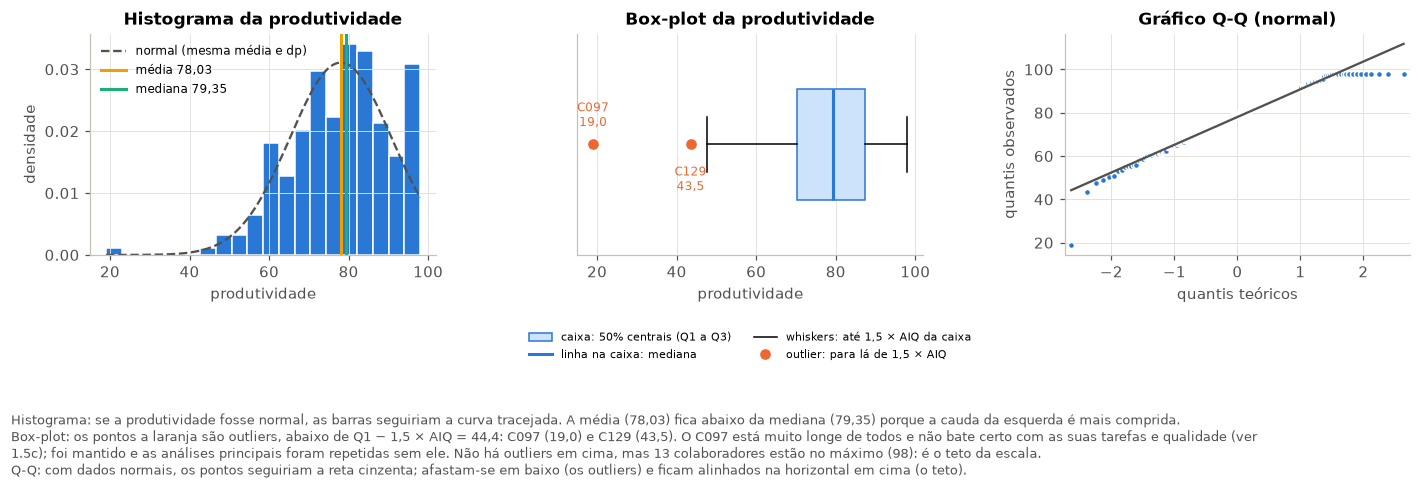

Média = 78.03 | mediana = 79.35 | Shapiro-Wilk W = 0.966, p = 2.1e-05
Sem C097: média = 78.28 | mediana = 79.50 | Shapiro-Wilk p = 0.00087


In [19]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 2.4 · Simetria da produtividade
# O quê: histograma com a curva normal de referência, box-plot e gráfico Q-Q (Figura 2);
# depois o teste de Shapiro-Wilk, com e sem C097.
# Porquê três gráficos: cada um mostra uma coisa (a forma, os valores afastados, a distância à normal).
# Leitura: cauda mais comprida à esquerda e teto em 98; a distribuição não é simétrica nem normal.
# ────────────────────────────────────────────────────────────────────────────────────────
fora, lim_inf, lim_sup = outliers_aiq(p)
ids_fora = df.loc[fora.index, "id_colaborador"]
n_teto = int((p == p.max()).sum())
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(p, bins=20, color=AZUL, edgecolor="white", density=True)
x = np.linspace(p.min(), p.max(), 200)
ax[0].plot(x, st.norm.pdf(x, p.mean(), p.std()), color=CINZA_TXT, lw=1.5, ls="--", label="normal (mesma média e dp)")
ax[0].axvline(p.mean(), color=AMARELO, lw=2, label=f"média {fpt(p.mean(), 2)}")
ax[0].axvline(p.median(), color=AQUA, lw=2, label=f"mediana {fpt(p.median(), 2)}")
ax[0].legend(fontsize=8, frameon=False, loc="upper left")
ax[0].set(title="Histograma da produtividade", xlabel="produtividade", ylabel="densidade")
ax[1].boxplot(p, vert=False, widths=.5, patch_artist=True,
              boxprops=dict(facecolor="#cde2fb", color=AZUL), medianprops=dict(color=AZUL, lw=2),
              flierprops=dict(marker="o", markerfacecolor=LARANJA, markeredgecolor="white", markersize=8))
for k, (i, v) in enumerate(fora.sort_values().items()):
    ax[1].annotate(f"{ids_fora[i]}\n{fpt(v)}", (v, 1), xytext=(0, 12 if k % 2 == 0 else -30),
                   textcoords="offset points", ha="center", fontsize=8, color=LARANJA)
ax[1].set(title="Box-plot da produtividade", xlabel="produtividade", yticks=[])
legenda_boxplot(ax[1])
qq(p, ax[2], "Gráfico Q-Q (normal)")
plt.tight_layout()
lista = " e ".join(f"{ids_fora[i]} ({fpt(v)})" for i, v in fora.sort_values().items())
nota(fig, f"Histograma: se a produtividade fosse normal, as barras seguiriam a curva tracejada. A média ({fpt(p.mean(), 2)}) "
          f"fica abaixo da mediana ({fpt(p.median(), 2)}) porque a cauda da esquerda é mais comprida.\n"
          f"Box-plot: os pontos a laranja são outliers, abaixo de Q1 − 1,5 × AIQ = {fpt(lim_inf)}: {lista}. O C097 está muito "
          f"longe de todos e não bate certo com as suas tarefas e qualidade (ver 1.5c); foi mantido e as análises principais "
          f"foram repetidas sem ele. Não há outliers em cima, mas {n_teto} colaboradores estão no máximo ({p.max():.0f}): "
          f"é o teto da escala.\n"
          f"Q-Q: com dados normais, os pontos seguiriam a reta cinzenta; afastam-se em baixo (os outliers) e ficam "
          f"alinhados na horizontal em cima (o teto).")
guardar(fig, "fig_2_4_produtividade"); plt.show()

# Shapiro-Wilk: H0 = a produtividade segue uma distribuição normal
sw = st.shapiro(p)
print(f"Média = {p.mean():.2f} | mediana = {p.median():.2f} | Shapiro-Wilk W = {sw.statistic:.3f}, p = {sw.pvalue:.2g}")
p_sem = p[df.loc[p.index, "id_colaborador"] != "C097"]
print(f"Sem C097: média = {p_sem.mean():.2f} | mediana = {p_sem.median():.2f} | Shapiro-Wilk p = {st.shapiro(p_sem).pvalue:.2g}")

Não é bem simétrica. O histograma e o box-plot mostram uma cauda mais comprida à esquerda (alguns valores baixos isolados, sobretudo o C097), e a média (78,0) fica abaixo da mediana (79,35), o que é típico desta forma. No gráfico Q-Q, os pontos afastam-se da reta na ponta de baixo. Na ponta de cima nota-se o teto em 98 (13 colaboradores), que «corta» a distribuição.

O teste de Shapiro-Wilk confirma o que os gráficos mostram: rejeita a normalidade (p < 0,001), mesmo sem o C097. Isto não impede o intervalo de confiança da média (4.6): com 238 colaboradores e um desvio moderado, o intervalo com a distribuição t continua adequado. Mas pesa nas escolhas seguintes: é por isso que, ao lado do Pearson e da ANOVA, usamos testes de confirmação que não a exigem (Spearman e Kruskal-Wallis) e, nas regressões, repetimos a análise sem o C097.

### 2.5. Colaborador mais produtivo vs. colaborador que mais usa IA

In [20]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 2.5 · Mais produtivo vs quem mais usa IA
# O quê: lista os 13 colaboradores empatados na produtividade máxima (98), desempata pela
# qualidade e pelas tarefas concluídas (C237) e mostra quem mais usa IA (C134, 25 h).
# Leitura: não são a mesma pessoa e C134 está abaixo da média: muito uso de IA não garante
# produtividade elevada.
# ────────────────────────────────────────────────────────────────────────────────────────
cols = ["id_colaborador", "departamento", "uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "produtividade"]
top_prod = df[df.produtividade == df.produtividade.max()]
print(f"Produtividade máxima = {df.produtividade.max()} — atingida por {len(top_prod)} colaboradores:")
display(top_prod[cols].sort_values("uso_ia_horas"))
# Desempate entre os 13 empatados em 98: maior qualidade do trabalho e, depois, mais tarefas concluídas
desempate = top_prod.sort_values(["qualidade_trabalho", "tarefas_concluidas"], ascending=False)
print("Desempate (qualidade do trabalho, depois tarefas concluídas):")
display(desempate[["id_colaborador", "departamento", "uso_ia_horas", "experiencia_anos", "qualidade_trabalho",
                   "tarefas_concluidas", "produtividade"]].head(3))
print("Colaborador com maior uso de IA:")
mais_ia = df.loc[[df.uso_ia_horas.idxmax()], cols]
display(mais_ia)
prod_mais_ia = mais_ia["produtividade"].iloc[0]
# quantos colaboradores são mais produtivos do que quem mais usa IA
print(f"Percentagem de colaboradores com produtividade superior a {prod_mais_ia}: {100 * (p > prod_mais_ia).mean():.0f}%")

Produtividade máxima = 98.0 — atingida por 13 colaboradores:


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,formacao_ia_horas,produtividade
13,C014,Operações,4.900,19.000,4.100,98.000
23,C024,Operações,5.400,9.400,10.800,98.000
56,C057,Análise de Dados,5.500,15.700,4.200,98.000
38,C039,Operações,7.700,4.800,6.400,98.000
177,C178,Análise de Dados,8.500,19.000,17.100,98.000
61,C062,Análise de Dados,8.600,7.900,4.900,98.000
14,C015,Comunicação,10.000,19.000,6.500,98.000
162,C163,Desenvolvimento,10.100,8.900,2.300,98.000
168,C169,Análise de Dados,11.800,5.800,17.300,98.000
182,C183,Operações,12.600,17.700,1.700,98.000


Desempate (qualidade do trabalho, depois tarefas concluídas):


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,qualidade_trabalho,tarefas_concluidas,produtividade
237,C237,Desenvolvimento,12.700,4.200,100.000,40,98.000
162,C163,Desenvolvimento,10.100,8.900,100.000,37,98.000
182,C183,Operações,12.600,17.700,98.700,40,98.000


Colaborador com maior uso de IA:


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,formacao_ia_horas,produtividade
133,C134,Desenvolvimento,25.000,8.300,36.000,71.600


Percentagem de colaboradores com produtividade superior a 71.6: 71%


A produtividade máxima (**98**) é atingida por **13 colaboradores** (o teto de que falámos), com usos de IA muito diferentes: de 4,9 h (C014) a 16,3 h (C036). Vários deles têm muita experiência: C014, C015 e C178 têm 19 anos. Se for preciso escolher um só, desempatamos pela qualidade do trabalho e depois pelo número de tarefas concluídas: fica o **C237** (Desenvolvimento), com qualidade 100, 40 tarefas e 12,7 h de IA por semana, acima da mediana mas longe do máximo.

Quem mais usa IA é o **C134 (25 h por semana)**, com produtividade **71,6**, abaixo da média e da mediana: cerca de 71% dos colaboradores são mais produtivos do que ele. Não é a mesma pessoa. Conclusão: usar muita IA não garante ser muito produtivo. Se houver uma relação entre as duas coisas, será uma tendência média, com muitas exceções, e não uma regra.

---
## 3. A utilização de IA está associada à produtividade?

### 3.1. Representação gráfica

n = 236


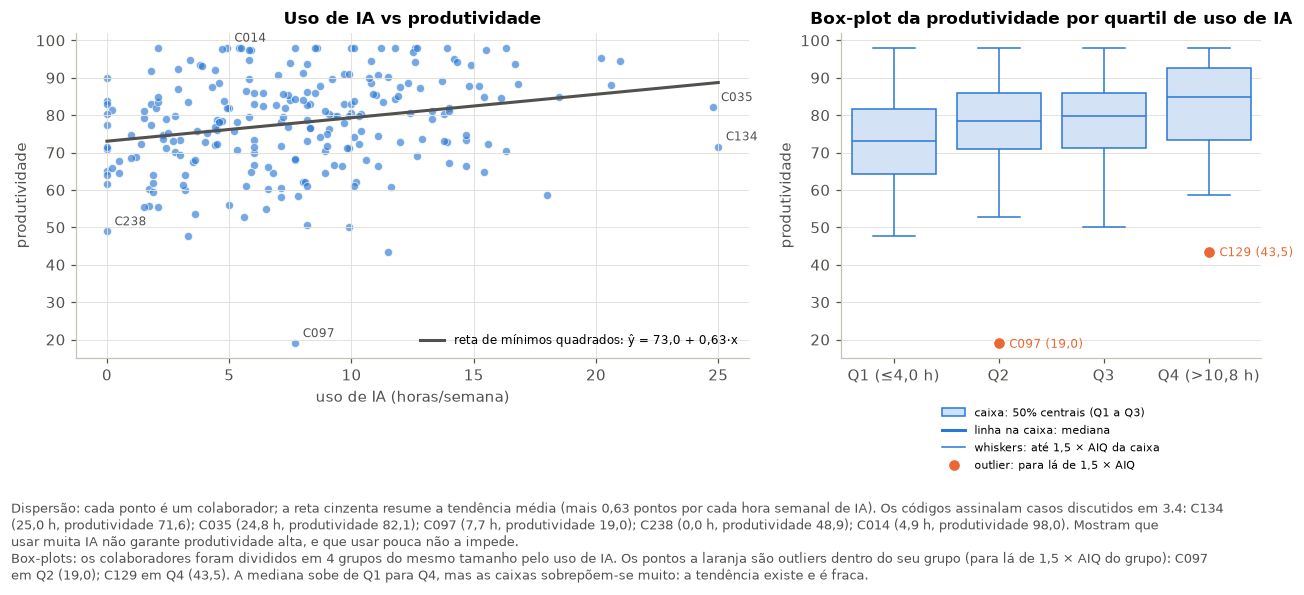

,count,mean,median,min,max
quartil_IA,,,,,
"Q1 (≤4,0 h)",59,73.100,73.000,47.600,97.900
Q2,63,77.800,78.400,19.000,98.000
Q3,56,78.100,79.800,50.200,98.000
"Q4 (>10,8 h)",58,82.700,84.900,43.500,98.000


In [21]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 3.1 · Gráfico da relação entre IA e produtividade
# O quê: gráfico de dispersão com a reta de mínimos quadrados e box-plots da produtividade
# por quartil de uso de IA (Figura 3).
# Porquê: as duas variáveis são quantitativas, por isso o gráfico adequado é a dispersão; as
# caixas por quartil tornam a tendência visível apesar da grande dispersão.
# Leitura: tendência crescente mas ténue; não há curvatura, por isso uma reta é razoável.
# ────────────────────────────────────────────────────────────────────────────────────────
d3 = df.dropna(subset=["uso_ia_horas", "produtividade"]).copy()
print("n =", len(d3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].scatter(d3.uso_ia_horas, d3.produtividade, s=28, color=AZUL, alpha=.65, edgecolor="white", linewidth=.6)
reta = smf.ols("produtividade ~ uso_ia_horas", data=d3).fit().params
b0, b1 = reta["Intercept"], reta["uso_ia_horas"]
xx = np.linspace(0, 25, 50)
ax[0].plot(xx, b0 + b1 * xx, color=CINZA_TXT, lw=2, label=f"reta de mínimos quadrados: ŷ = {fpt(b0)} + {fpt(b1, 2)}·x")
destaque = ["C134", "C035", "C097", "C238", "C014"]          # casos discutidos em 3.4
for cid in destaque:
    r = d3[d3.id_colaborador == cid].iloc[0]
    ax[0].annotate(cid, (r.uso_ia_horas, r.produtividade), xytext=(5, 4), textcoords="offset points",
                   fontsize=8, color=CINZA_TXT)
ax[0].set(title="Uso de IA vs produtividade", xlabel="uso de IA (horas/semana)", ylabel="produtividade")
ax[0].legend(frameon=False, fontsize=8, loc="lower right")

# divide os colaboradores em 4 grupos com o mesmo número de pessoas, por nível de uso de IA
_, cortes = pd.qcut(d3.uso_ia_horas, 4, retbins=True)          # limites reais dos quartis
d3["quartil_IA"] = pd.qcut(d3.uso_ia_horas, 4, labels=[f"Q1 (≤{fpt(cortes[1])} h)", "Q2", "Q3",
                                                        f"Q4 (>{fpt(cortes[3])} h)"])
sns.boxplot(data=d3, x="quartil_IA", y="produtividade", ax=ax[1], color="#cde2fb", linecolor=AZUL,
            flierprops=dict(markerfacecolor=LARANJA, markeredgecolor="white", markersize=8))
# outliers de cada grupo (a regra do box-plot aplica-se dentro de cada quartil)
fora_q = []
for k, (q, g) in enumerate(d3.groupby("quartil_IA", observed=True)):
    fo, _, _ = outliers_aiq(g.produtividade)
    for i, v in fo.items():
        fora_q.append((q, d3.loc[i, "id_colaborador"], v))
        ax[1].annotate(f"{d3.loc[i, 'id_colaborador']} ({fpt(v)})", (k, v), xytext=(7, -3),
                       textcoords="offset points", fontsize=8, color=LARANJA)
ax[1].set(title="Box-plot da produtividade por quartil de uso de IA", xlabel="", ylabel="produtividade")
legenda_boxplot(ax[1], cor_linhas=AZUL, ncol=1, y=-0.12)
plt.tight_layout()
casos = "; ".join(f"{cid} ({fpt(r.uso_ia_horas)} h, produtividade {fpt(r.produtividade)})"
                  for cid in destaque for _, r in d3[d3.id_colaborador == cid].iterrows())
lista_q = "; ".join(f"{cid} em {str(q).split(' ')[0]} ({fpt(v)})" for q, cid, v in fora_q) or "nenhum"
nota(fig, f"Dispersão: cada ponto é um colaborador; a reta cinzenta resume a tendência média (mais {fpt(b1, 2)} pontos por "
          f"cada hora semanal de IA). Os códigos assinalam casos discutidos em 3.4: {casos}. Mostram que usar muita IA não "
          f"garante produtividade alta, e que usar pouca não a impede.\n"
          f"Box-plots: os colaboradores foram divididos em 4 grupos do mesmo tamanho pelo uso de IA. Os pontos a laranja são "
          f"outliers dentro do seu grupo (para lá de 1,5 × AIQ do grupo): {lista_q}. A mediana sobe de Q1 para Q4, mas as "
          f"caixas sobrepõem-se muito: a tendência existe e é fraca.")
guardar(fig, "fig_3_1_dispersao"); plt.show()
display(d3.groupby("quartil_IA", observed=True).produtividade.agg(["count", "mean", "median", "min", "max"]).round(1))

A nuvem de pontos mostra uma tendência a subir, mas fraca. Em média, quem usa mais IA é um pouco mais produtivo: a mediana passa de 73,0 no quarto de colaboradores que menos usa IA para 84,9 no quarto que mais usa. Mas a dispersão é enorme em qualquer nível de uso: com cerca de 8 h por semana há produtividades entre 19 e 98. Não se vê nenhuma curva, por isso uma reta descreve razoavelmente a tendência.

### 3.2. Intensidade e direção da associação

In [22]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 3.2 · Intensidade e direção da associação
# O quê: coeficiente de Pearson (associação linear) e de Spearman (baseado nas ordens), r² e
# Pearson sem C097.
# Porquê Pearson: duas variáveis quantitativas com relação aproximadamente linear.
# Porquê também Spearman: a produtividade não é normal e tem atípicos e teto; o Spearman é menos
# sensível a isso. Se os dois concordarem, a conclusão não depende dessas características.
# Leitura: r = 0,24 e ρ = 0,27, positiva e fraca; r² = 0,06.
# ────────────────────────────────────────────────────────────────────────────────────────
r_p = st.pearsonr(d3.uso_ia_horas, d3.produtividade)
r_s = st.spearmanr(d3.uso_ia_horas, d3.produtividade)
print(f"Pearson  r   = {r_p.statistic:.3f}, p = {r_p.pvalue:.2g}")
print(f"Spearman rho = {r_s.statistic:.3f}, p = {r_s.pvalue:.2g}")
print(f"r² = {r_p.statistic**2:.3f}")
d3s = d3[d3.id_colaborador != "C097"]
print(f"Pearson sem C097: r = {st.pearsonr(d3s.uso_ia_horas, d3s.produtividade).statistic:.3f}")
d3i = d3[~d3.id_colaborador.isin(INCOERENTES)]
r_pi = st.pearsonr(d3i.uso_ia_horas, d3i.produtividade)
print(f"Pearson sem os {len(d3) - len(d3i)} casos marcados em 1.5d: r = {r_pi.statistic:.3f}, p = {r_pi.pvalue:.2g} (n = {len(d3i)})")

Pearson  r   = 0.241, p = 0.00019
Spearman rho = 0.266, p = 3.5e-05
r² = 0.058
Pearson sem C097: r = 0.252
Pearson sem os 10 casos marcados em 1.5d: r = 0.241, p = 0.00026 (n = 226)


**Que medida usámos e porquê.** As duas variáveis são quantitativas e o gráfico mostra uma relação aproximadamente em linha reta, por isso a medida indicada é o coeficiente de correlação de **Pearson**. Como a produtividade não é normal, tem valores muito afastados e um teto em 98, calculámos também o de **Spearman**, que trabalha com as posições (ordens) dos valores e por isso é menos sensível a esses problemas. É o que a docente recomenda nestes casos.

**Resultado.** r = 0,24 (p < 0,001) e ρ = 0,27 (p < 0,001). A relação é positiva (quando uma sobe, a outra tende a subir) e estatisticamente diferente de zero. Os dois coeficientes dizem o mesmo e, sem o C097, r quase não muda (0,25): o resultado não se deve a um valor estranho. Sem os 10 colaboradores com tarefas e tempo incoerentes (1.5d), r = 0,24 (p < 0,001; n = 226): a conclusão mantém-se.

### 3.3. Classificação da associação

A associação é **fraca**. Na escala que a docente usa nos infográficos de Pearson e de Spearman, valores entre 0,2 e 0,4 são uma associação fraca (abaixo de 0,2 é muito fraca ou inexistente; a partir de 0,6, forte). Com r = 0,24 estamos no início desse intervalo.

Outra forma de ver: r² ≈ 0,06, ou seja, o uso de IA sozinho só acompanha cerca de 6% da variação da produtividade; os outros 94% dependem de outras coisas. O valor-p muito pequeno não torna a associação forte: com 236 pessoas, até uma relação fraca se distingue do zero. Significativo não quer dizer forte.

### 3.4. Os que mais usam IA são necessariamente os mais produtivos?

In [23]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 3.4 · Quem mais usa IA é sempre mais produtivo?
# O quê: lista os 10 maiores utilizadores de IA e os 11 que não usam IA, para encontrar exemplos
# concretos que contrariam a regra (pedido explícito do enunciado).
# ────────────────────────────────────────────────────────────────────────────────────────
cols = ["id_colaborador", "departamento", "uso_ia_horas", "experiencia_anos", "produtividade"]
print("10 colaboradores com MAIOR uso de IA:")
display(d3.nlargest(10, "uso_ia_horas")[cols])
print("Colaboradores que NÃO usam IA (0 h):")
display(d3[d3.uso_ia_horas == 0][cols].sort_values("produtividade"))
print(f"Produtividade média global: {d3.produtividade.mean():.1f}")

10 colaboradores com MAIOR uso de IA:


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,produtividade
133,C134,Desenvolvimento,25.000,8.300,71.600
34,C035,Comunicação,24.800,4.800,82.100
51,C052,Análise de Dados,21.000,5.300,94.600
15,C016,Operações,20.600,15.000,88.000
236,C236,Desenvolvimento,20.200,8.100,95.400
37,C038,Operações,18.500,7.400,84.900
77,C078,Desenvolvimento,18.000,1.400,58.700
87,C088,Desenvolvimento,16.800,15.800,88.400
240,C240,Desenvolvimento,16.700,9.700,93.700
3,C004,Análise de Dados,16.300,2.000,70.300


Colaboradores que NÃO usam IA (0 h):


,id_colaborador,departamento,uso_ia_horas,experiencia_anos,produtividade
238,C238,Análise de Dados,0.000,5.700,48.900
152,C153,Comunicação,0.000,4.500,61.600
173,C174,Desenvolvimento,0.000,0.800,64.100
100,C101,Análise de Dados,0.000,5.900,65.200
44,C045,Operações,0.000,3.200,70.900
78,C079,Operações,0.000,4.000,71.600
92,C093,Operações,0.000,2.800,77.500
239,C239,Comunicação,0.000,2.200,80.200
161,C162,Desenvolvimento,0.000,5.200,83.100
132,C133,Análise de Dados,0.000,0.500,83.800


Produtividade média global: 77.9


Não. Alguns exemplos concretos:
- O C134 usa IA 25 h por semana (o máximo) e tem produtividade 71,6, abaixo da média de 78; o C078 usa 18 h e tem 58,7; o C004 usa 16,3 h e tem 70,3.
- No sentido contrário, o C014 usa só 4,9 h e atinge o máximo (98); o C053 não usa IA e tem 90.
- Entre os 11 colaboradores que não usam IA, a produtividade vai de 48,9 (C238) a 90,0 (C053), uma amplitude parecida com a de quem usa muita IA.

Reparámos ainda que, entre os que usam muita IA e são muito produtivos, vários têm bastante experiência (C016 e C088, com 15 a 16 anos). Isto faz suspeitar que a experiência pode estar por trás da relação: um «fator de confusão», ou seja, algo que influencia ao mesmo tempo o uso de IA e a produtividade. Voltamos a isto no capítulo 6.

### 3.5. Associação e causalidade

Não. Os dados foram recolhidos num único momento e ninguém decidiu ao acaso quem usava IA. Nestas condições, uma correlação positiva pode ter várias explicações:
1. **um terceiro fator** que influencia as duas coisas ao mesmo tempo, como a experiência (r = 0,27 com o uso de IA e 0,50 com a produtividade, ver 6.1) ou a formação em IA (r = 0,51 com o uso de IA);
2. **causa ao contrário**: os colaboradores mais produtivos podem ter mais tempo ou autonomia para experimentar a IA;
3. **escolha pessoal**: quem decide usar IA pode ser diferente, à partida, de quem não usa.

A correlação diz-nos que as duas coisas tendem a aparecer juntas, não que uma provoca a outra. Para falar de causa seria preciso uma experiência (por exemplo, dar acesso à IA a equipas escolhidas ao acaso) ou, pelo menos, ter em conta os outros fatores, que é o que fazemos no capítulo 6.

---
## 4. Existem diferenças estatisticamente relevantes?

### 4.1. Produtividade por departamento

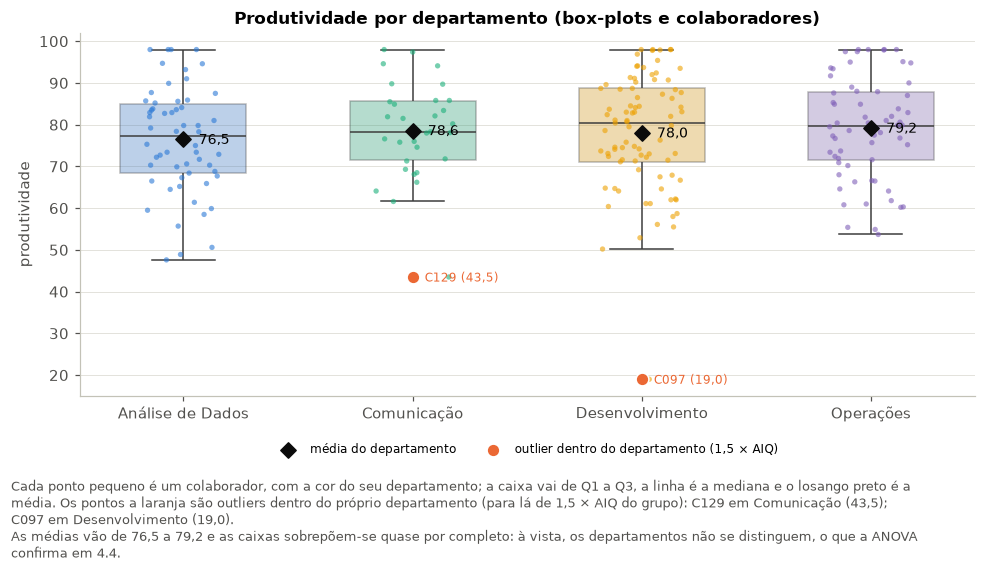

,count,mean,std,min,25%,50%,75%,max
departamento,,,,,,,,
Análise de Dados,58.000,76.470,12.570,47.600,68.500,77.400,84.920,98.000
Comunicação,31.000,78.600,11.610,43.500,71.550,78.300,85.650,98.000
Desenvolvimento,85.000,78.030,13.970,19.000,71.100,80.400,88.700,98.000
Operações,64.000,79.180,12.200,53.700,71.420,79.700,87.930,98.000


In [24]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 4.1 · Produtividade por departamento (gráfico)
# O quê: box-plots com os pontos individuais e a média de cada departamento (Figura 4), e
# estatísticas por departamento.
# Leitura: médias muito parecidas (76,5 a 79,2) e caixas quase sobrepostas.
# ────────────────────────────────────────────────────────────────────────────────────────
ordem = ["Análise de Dados", "Comunicação", "Desenvolvimento", "Operações"]
# cores dos departamentos sem laranja, que fica reservado aos outliers
cores_dep = dict(zip(ordem, [AZUL, AQUA, AMARELO, "#7f5fb8"]))
d4 = df.dropna(subset=["produtividade"])

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.boxplot(data=d4, x="departamento", y="produtividade", order=ordem, hue="departamento",
            palette=cores_dep, ax=ax, width=.55, legend=False, boxprops=dict(alpha=.35),
            showfliers=False)
sns.stripplot(data=d4, x="departamento", y="produtividade", order=ordem, hue="departamento",
              palette=cores_dep, ax=ax, size=3.5, alpha=.6, jitter=.18, legend=False)
# outliers dentro de cada departamento (regra do box-plot aplicada a cada grupo)
fora_dep = []
for k, dep in enumerate(ordem):
    fo, _, _ = outliers_aiq(d4[d4.departamento == dep].produtividade)
    for i, v in fo.items():
        fora_dep.append((dep, d4.loc[i, "id_colaborador"], v))
        ax.scatter(k, v, s=70, color=LARANJA, edgecolor="white", zorder=6)
        ax.annotate(f"{d4.loc[i, 'id_colaborador']} ({fpt(v)})", (k, v), xytext=(8, -3),
                    textcoords="offset points", fontsize=8, color=LARANJA)
medias = d4.groupby("departamento").produtividade.mean().reindex(ordem)
ax.scatter(range(4), medias, marker="D", s=50, color="#0b0b0b", zorder=5, label="média do departamento")
for i, m in enumerate(medias):
    ax.annotate(fpt(m), (i, m), xytext=(10, -3), textcoords="offset points", fontsize=9)
ax.scatter([], [], s=70, color=LARANJA, edgecolor="white", label="outlier dentro do departamento (1,5 × AIQ)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set(title="Produtividade por departamento (box-plots e colaboradores)", xlabel="")
plt.tight_layout()
lista = "; ".join(f"{cid} em {dep} ({fpt(v)})" for dep, cid, v in fora_dep) or "nenhum"
nota(fig, f"Cada ponto pequeno é um colaborador, com a cor do seu departamento; a caixa vai de Q1 a Q3, a linha é a mediana "
          f"e o losango preto é a média. Os pontos a laranja são outliers dentro do próprio departamento (para lá de "
          f"1,5 × AIQ do grupo): {lista}.\n"
          f"As médias vão de {fpt(medias.min())} a {fpt(medias.max())} e as caixas sobrepõem-se quase por completo: à vista, "
          f"os departamentos não se distinguem, o que a ANOVA confirma em 4.4.")
guardar(fig, "fig_4_1_departamentos"); plt.show()
display(d4.groupby("departamento").produtividade.describe().round(2))

As médias são muito parecidas (76,5 a 79,2) e as caixas quase se sobrepõem. A maior diferença (2,7 pontos, entre Operações e Análise de Dados) é pequena face à variação dentro de cada departamento (desvios-padrão entre 11,6 e 14,0). À primeira vista não há diferenças importantes, mas é preciso confirmar com um teste.

### 4.2. Hipóteses estatísticas

Sendo μ<sub>AD</sub>, μ<sub>C</sub>, μ<sub>D</sub> e μ<sub>O</sub> as produtividades médias (na população) de Análise de Dados, Comunicação, Desenvolvimento e Operações:

- H₀: μ<sub>AD</sub> = μ<sub>C</sub> = μ<sub>D</sub> = μ<sub>O</sub> (a produtividade média é igual nos quatro departamentos)
- H₁: pelo menos dois departamentos têm médias diferentes

Para o teste de Kruskal-Wallis, que usamos como confirmação, as hipóteses falam das distribuições e não só das médias: H₀, a produtividade distribui-se da mesma forma nos quatro departamentos; H₁, pelo menos um departamento tende a ter valores mais altos ou mais baixos.

### 4.3. Condições de aplicação

In [25]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 4.3 · Condições de aplicação da ANOVA
# O quê: verifica as condições antes de escolher o teste: normalidade em cada grupo (Shapiro-Wilk)
# e igualdade das variâncias (Levene). A independência garante-se pelo desenho (cada colaborador
# aparece uma vez e pertence a um só departamento).
# Leitura: normalidade rejeitada só em Desenvolvimento, e continua rejeitada sem C097;
# variâncias homogéneas.
# ────────────────────────────────────────────────────────────────────────────────────────
grupos = {g: x.produtividade.values for g, x in d4.groupby("departamento")}
cond = pd.DataFrame({
    "n": {g: len(v) for g, v in grupos.items()},
    "Shapiro-Wilk p": {g: st.shapiro(v).pvalue for g, v in grupos.items()},
    "desvio-padrão": {g: v.std(ddof=1) for g, v in grupos.items()},
})
display(cond.round(4))
# Levene: H0 = as variâncias são iguais nos 4 departamentos (center='median' é a versão robusta)
lev = st.levene(*grupos.values(), center="median")
print(f"Levene: W = {lev.statistic:.3f}, p = {lev.pvalue:.3f}")
dev_s = d4[(d4.departamento == "Desenvolvimento") & (d4.id_colaborador != "C097")].produtividade
print(f"Shapiro-Wilk em Desenvolvimento sem C097: p = {st.shapiro(dev_s).pvalue:.3f} (n = {len(dev_s)})")

,n,Shapiro-Wilk p,desvio-padrão
Análise de Dados,58,0.363,12.570
Comunicação,31,0.317,11.607
Desenvolvimento,85,0.000,13.973
Operações,64,0.063,12.197


Levene: W = 0.751, p = 0.523
Shapiro-Wilk em Desenvolvimento sem C097: p = 0.027 (n = 84)


Antes de escolher o teste, verificámos as três condições da ANOVA a um fator, como no guião da aula 3 e nos infográficos da docente:

- **Independência**: garantida pela forma como os dados foram recolhidos. Cada colaborador aparece uma só vez (depois de retirar o duplicado) e pertence a um único departamento.
- **Normalidade em cada grupo** (Shapiro-Wilk): não é rejeitada em Análise de Dados (p = 0,36), Comunicação (p = 0,32) e Operações (p = 0,06); é rejeitada em Desenvolvimento (p < 0,001), o grupo onde está o C097. Sem ele o desvio é muito menor, mas o teste continua a rejeitar (p = 0,03). Como a docente sublinha, a decisão não depende só do valor-p: os grupos são grandes (31 a 85 colaboradores) e a ANOVA aguenta bem desvios moderados da normalidade quando os grupos são grandes e as variâncias parecidas.
- **Variâncias iguais** (Levene): p = 0,52, não rejeitamos a igualdade. Os desvios-padrão são parecidos (11,6 a 14,0).

**Decisão, tomada antes de ver o resultado.** Seguimos o fluxograma da docente: com o Levene a não rejeitar a igualdade das variâncias, o teste indicado é a **ANOVA a um fator**. Juntámos duas confirmações que também constam dos materiais da docente: a **ANOVA de Welch**, que não exige variâncias iguais (útil porque os grupos têm tamanhos muito diferentes), e o **Kruskal-Wallis**, que não exige normalidade (útil por causa do grupo Desenvolvimento). Se os três disserem o mesmo, a conclusão é mais segura.

Não fizemos vários testes t entre pares de departamentos: com 4 departamentos seriam 6 testes, e a probabilidade de encontrar pelo menos uma diferença «falsa» subia para cerca de 26%.

### 4.4. Análise e valor-p

In [26]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 4.4a · ANOVA a um fator e Kruskal-Wallis
# O quê: ANOVA (compara as médias dos 4 departamentos) como teste principal; Kruskal-Wallis
# (não exige normalidade) como confirmação; eta quadrado (tamanho do efeito) e ANOVA sem C097.
# Porquê ANOVA e não vários testes t: com 4 grupos seriam 6 testes t e o risco de uma diferença
# «falsa» subia para cerca de 26%. Porquê Kruskal-Wallis: a normalidade falha num dos grupos.
# Leitura: p = 0,70 e 0,71, não se rejeita H0; η² = 0,006, abaixo do limiar de efeito pequeno.
# ────────────────────────────────────────────────────────────────────────────────────────
anova = st.f_oneway(*grupos.values())
# Kruskal-Wallis: não exige normalidade
kw = st.kruskal(*grupos.values())
print(f"ANOVA: F(3, {len(d4) - 4}) = {anova.statistic:.3f}, p = {anova.pvalue:.3f}")
print(f"Kruskal-Wallis: H(3) = {kw.statistic:.3f}, p = {kw.pvalue:.3f}")
# eta quadrado = parte da variabilidade total explicada pelas diferenças entre departamentos
media_global = d4.produtividade.mean()
ss_entre = sum(len(g) * (g.produtividade.mean() - media_global) ** 2 for _, g in d4.groupby("departamento"))
ss_total = ((d4.produtividade - media_global) ** 2).sum()
print(f"Eta quadrado (SS entre / SS total) = {ss_entre / ss_total:.4f}  "
      "(referência da docente: 0,01 pequeno · 0,06 médio · 0,14 grande)")
d4s = d4[d4.id_colaborador != "C097"]
print(f"ANOVA sem C097: p = {st.f_oneway(*[x.produtividade for _, x in d4s.groupby('departamento')]).pvalue:.3f}")
d4i = d4[~d4.id_colaborador.isin(INCOERENTES)]
print(f"ANOVA sem os {len(d4) - len(d4i)} casos marcados em 1.5d: "
      f"p = {st.f_oneway(*[x.produtividade for _, x in d4i.groupby('departamento')]).pvalue:.3f} (n = {len(d4i)})")

ANOVA: F(3, 234) = 0.472, p = 0.702
Kruskal-Wallis: H(3) = 1.367, p = 0.713
Eta quadrado (SS entre / SS total) = 0.0060  (referência da docente: 0,01 pequeno · 0,06 médio · 0,14 grande)
ANOVA sem C097: p = 0.632
ANOVA sem os 10 casos marcados em 1.5d: p = 0.557 (n = 228)


In [27]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 4.4b · ANOVA de Welch
# O quê: segunda confirmação, que não exige variâncias iguais (útil porque os grupos têm dimensões
# muito diferentes, de 31 a 85). Leitura: p = 0,68, a mesma conclusão.
# ────────────────────────────────────────────────────────────────────────────────────────
from statsmodels.stats.oneway import anova_oneway
welch = anova_oneway(d4.produtividade, d4.departamento, use_var="unequal")
print(f"ANOVA de Welch: F(3; {welch.df_denom:.1f}) = {welch.statistic:.3f}, p = {welch.pvalue:.3f}")

ANOVA de Welch: F(3; 105.7) = 0.503, p = 0.681


ANOVA: **F(3, 234) = 0,47; p = 0,70**. ANOVA de Welch: F(3; 105,7) = 0,50; p = 0,68. Kruskal-Wallis: H(3) = 1,37; p = 0,71. Sem o C097, a ANOVA dá p = 0,63; sem os 10 casos marcados em 1.5d, p = 0,56.

**Como se lê o valor-p de 0,70.** Se a produtividade média fosse mesmo igual nos quatro departamentos, diferenças como as que observámos (ou maiores) apareceriam em cerca de 70% das amostras. As diferenças que vimos explicam-se perfeitamente pelo acaso. Como p > 0,05, não rejeitamos H₀. Os três testes concordam e o resultado não depende do C097 nem dos casos marcados em 1.5d.

**Tamanho do efeito.** O η² (eta quadrado) é 0,006: o departamento explica só 0,6% da variação da produtividade. Pela referência da docente (0,01 pequeno, 0,06 médio, 0,14 grande), nem chega a um efeito pequeno.

### 4.5. O que podemos afirmar e o que fica por esclarecer

**O que podemos afirmar:** com estes dados, não há evidência de que a produtividade média seja diferente entre departamentos; as diferenças observadas (no máximo 2,7 pontos) são compatíveis com o acaso. Por isso não fizemos comparações par a par (teste de Tukey), que, segundo a docente, só se fazem depois de a ANOVA rejeitar H₀.

**O que não podemos afirmar:** que as médias são iguais. Não rejeitar H₀ não prova que H₀ é verdadeira. Pode haver pequenas diferenças que estes dados não detetam, sobretudo em Comunicação, que só tem 31 pessoas.

**O que fica por esclarecer:** se a IA tem o mesmo efeito em todos os departamentos, se a avaliação de produtividade é comparável entre trabalhos tão diferentes e se as diferenças de experiência e formação entre departamentos estão a esconder diferenças. Fica também uma informação útil: como o departamento não explica a produtividade, não deve estar por trás da relação entre IA e produtividade.

### 4.6. Intervalo de confiança a 95% para a produtividade média

In [28]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 4.6 · Intervalo de confiança a 95% para a produtividade média
# O quê: média ± t × erro-padrão, com a distribuição t de Student (n − 1 = 237 graus de liberdade).
# Porquê t e não normal: o desvio-padrão da população é desconhecido e é estimado pela amostra.
# Leitura: [76,4 ; 79,7]. Estima a MÉDIA; não é o intervalo onde estão 95% dos colaboradores.
# ────────────────────────────────────────────────────────────────────────────────────────
n, media, ep = len(p), p.mean(), st.sem(p)
# erro-padrão = desvio-padrão / raiz(n)
ic_t = st.t.interval(confidence=0.95, df=n - 1, loc=media, scale=ep)
print(f"n = {n} | média = {media:.2f} | erro-padrão = {ep:.3f}")
print(f"IC95% (t de Student): [{ic_t[0]:.2f} ; {ic_t[1]:.2f}]  (margem de erro = ±{ic_t[1] - media:.2f})")

n = 238 | média = 78.03 | erro-padrão = 0.832
IC95% (t de Student): [76.39 ; 79.67]  (margem de erro = ±1.64)


**IC 95% = [76,4 ; 79,7]**, ou seja, 78,0 ± 1,6 pontos. Usámos a distribuição t de Student porque não conhecemos o desvio-padrão da população; com 238 pessoas, t e normal dão praticamente o mesmo.

**Como se lê:** se repetíssemos a recolha muitas vezes e calculássemos o intervalo sempre da mesma maneira, cerca de 95% desses intervalos conteriam a verdadeira produtividade média. O intervalo é estreito, logo a média está bem estimada. Atenção: o intervalo é para a **média**; não diz que 95% dos colaboradores estão entre 76,4 e 79,7 (a maioria não está).

Como os dados são sintéticos, a «população» é o processo que gerou os dados, não uma empresa real. O intervalo mede só a incerteza de trabalhar com uma amostra; não cobre erros de medição, o teto em 98 nem possíveis erros de registo como o C097.

---
## 5. Podemos explicar a produtividade através da utilização de IA?

### 5.1. Modelo de regressão linear simples

In [29]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.1 · Regressão linear simples (modelo M1)
# O quê: estima produtividade = b0 + b1 × uso_IA por mínimos quadrados (n = 236).
# Leitura: o teste t ao declive dá p < 0,001, logo é possível construir a equação.
# ────────────────────────────────────────────────────────────────────────────────────────
d5 = df.dropna(subset=["uso_ia_horas", "produtividade"]).copy()
# smf.ols ajusta o modelo por mínimos quadrados; a fórmula lê-se «produtividade em função do uso de IA»
m1 = smf.ols("produtividade ~ uso_ia_horas", data=d5).fit()
print(m1.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:          produtividade   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.054
No. Observations:                 236   F-statistic:                     14.41
Covariance Type:            nonrobust   Prob (F-statistic):           0.000187
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       73.0397      1.519     48.094      0.000      70.048      76.032
uso_ia_horas     0.6273      0.165      3.796      0.000       0.302       0.953

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


Sim. As duas variáveis são quantitativas, a relação parece aproximadamente em linha reta (3.1) e o teste ao declive rejeita H₀: β₁ = 0 (t = 3,80; p < 0,001), isto é, há evidência de que a reta não é horizontal. Conseguimos escrever a equação. Se ela serve para prever é outra questão, que vemos em 5.4.

### 5.2. Equação e significado dos coeficientes

In [30]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.2 · Equação e significado dos coeficientes
# O quê: extrai b0 (produtividade estimada com 0 h de IA) e b1 (diferença média por hora de IA),
# com intervalos de confiança a 95%.
# ────────────────────────────────────────────────────────────────────────────────────────
b0, b1 = m1.params["Intercept"], m1.params["uso_ia_horas"]
ic = m1.conf_int()
print(f"produtividade_estimada = {b0:.2f} + {b1:.3f} × uso_ia_horas")
print(f"IC95% b0: [{ic.loc['Intercept', 0]:.2f} ; {ic.loc['Intercept', 1]:.2f}]")
print(f"IC95% b1: [{ic.loc['uso_ia_horas', 0]:.3f} ; {ic.loc['uso_ia_horas', 1]:.3f}]  | p = {m1.pvalues['uso_ia_horas']:.2g}")

produtividade_estimada = 73.04 + 0.627 × uso_ia_horas
IC95% b0: [70.05 ; 76.03]
IC95% b1: [0.302 ; 0.953]  | p = 0.00019


$$\widehat{\text{produtividade}} = 73{,}04 + 0{,}627 \times \text{uso\_ia\_horas}$$

- **Ordenada na origem** (b₀ = 73,04): produtividade média estimada para quem não usa IA (0 h por semana). Aqui faz sentido, porque há 11 colaboradores com 0 h.
- **Declive** (b₁ = 0,627; IC 95%: 0,30 a 0,95): por cada hora semanal a mais de IA, a produtividade média estimada é 0,63 pontos mais alta. É uma comparação entre pessoas diferentes, não o que acontece a uma pessoa se passar a usar mais IA.

### 5.3. Diferença estimada entre 5 h e 10 h semanais

In [31]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.3 · Diferença estimada entre 5 h e 10 h
# O quê: produtividade média estimada para 5 h e 10 h e a diferença (= 5 × b1, com IC 95%).
# mean_ci: IC para a MÉDIA de colaboradores com esse uso; obs_ci: intervalo para UM colaborador
# (muito mais largo). É uma comparação entre perfis, não o efeito de aumentar o uso.
# ────────────────────────────────────────────────────────────────────────────────────────
prev = m1.get_prediction(pd.DataFrame({"uso_ia_horas": [5, 10]})).summary_frame(alpha=.05)
prev.index = ["5 h", "10 h"]
display(prev.round(2))
print(f"Diferença estimada (10 h − 5 h) = 5 × b1 = {5 * b1:.2f} pontos "
      f"(IC95%: {5 * ic.loc['uso_ia_horas', 0]:.2f} a {5 * ic.loc['uso_ia_horas', 1]:.2f})")

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
5 h,76.180,0.930,74.340,78.010,51.540,100.810
10 h,79.310,0.890,77.560,81.070,54.680,103.940


Diferença estimada (10 h − 5 h) = 5 × b1 = 3.14 pontos (IC95%: 1.51 a 4.76)


Produtividade média estimada: **76,2** com 5 h e **79,3** com 10 h. A diferença é 5 × 0,627 ≈ **3,1 pontos** (IC 95%: 1,5 a 4,8).

Condições desta comparação:
- fala da **média** de colaboradores com esse uso, não de duas pessoas concretas. Para uma pessoa em particular, o intervalo de previsão com 5 h vai de cerca de 52 a 101: duas pessoas podem até diferir no sentido contrário;
- **não mantém nada constante**: quem usa 10 h tende também a ter mais experiência e formação, e isso está misturado nos 3,1 pontos (capítulo 6);
- é uma **associação, não um efeito causal**;
- 5 h e 10 h estão dentro dos valores observados (0 a 25 h), por isso **não estamos a extrapolar**;
- o limite de cima do intervalo de previsão passa de 100 (100,8 e 103,9), o que é impossível nesta escala: a reta não sabe que a escala acaba em 100. É mais um sinal do teto em 98 e de que o modelo descreve a tendência média, mas não serve para prever uma pessoa concreta.

### 5.4. Proporção da variabilidade explicada

In [32]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.4 · Proporção da variabilidade explicada
# O quê: R² (≈ 6%) e R² ajustado. O uso de IA, sozinho, explica pouco da produtividade.
# ────────────────────────────────────────────────────────────────────────────────────────
print(f"R² = {m1.rsquared:.4f} | R² ajustado = {m1.rsquared_adj:.4f}")

R² = 0.0580 | R² ajustado = 0.0540


**R² = 0,058**: o uso de IA explica cerca de 6% da variação da produtividade (R² ajustado: 5,4%). Os restantes 94% dependem de outras coisas. Saber quantas horas de IA uma pessoa usa ajuda muito pouco a prever a sua produtividade. Como a docente avisa na aula 4, um declive significativo não quer dizer que o modelo explique muito.

### 5.5. Um colaborador concreto: C001

In [33]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.5 · Um colaborador concreto (C001)
# O quê: compara a produtividade observada de C001 com a estimada pelo modelo.
# Resíduo = observado − estimado = 68,0 − 77,9 = −9,9: o modelo sobrestima C001 (pouca experiência).
# ────────────────────────────────────────────────────────────────────────────────────────
c = d5[d5.id_colaborador == "C001"]
obs = c.produtividade.iloc[0]; est = m1.predict(c).iloc[0]
print(f"C001: uso de IA = {c.uso_ia_horas.iloc[0]} h | produtividade observada = {obs:.1f} | "
      f"estimada = {est:.2f} | resíduo = {obs - est:.2f}")
display(c[["id_colaborador", "departamento", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas",
           "tarefas_concluidas", "qualidade_trabalho"]])

C001: uso de IA = 7.7 h | produtividade observada = 68.0 | estimada = 77.87 | resíduo = -9.87


,id_colaborador,departamento,experiencia_anos,formacao_ia_horas,complexidade_tarefas,tarefas_concluidas,qualidade_trabalho
0,C001,Operações,0.500,7.700,3.000,25,81.600


O C001 (Operações) usa IA 7,7 h por semana. O modelo estima 73,04 + 0,627 × 7,7 ≈ **77,9**, mas o valor real é **68,0**. A diferença, o **resíduo**, é de **−9,9 pontos**: é a parte da produtividade do C001 que o uso de IA não explica. Ele está cerca de 10 pontos abaixo de um colaborador típico com o mesmo uso de IA. Uma pista: o C001 tem apenas meio ano de experiência, o que antecipa o papel da experiência no modelo múltiplo.

### 5.6. Análise de resíduos

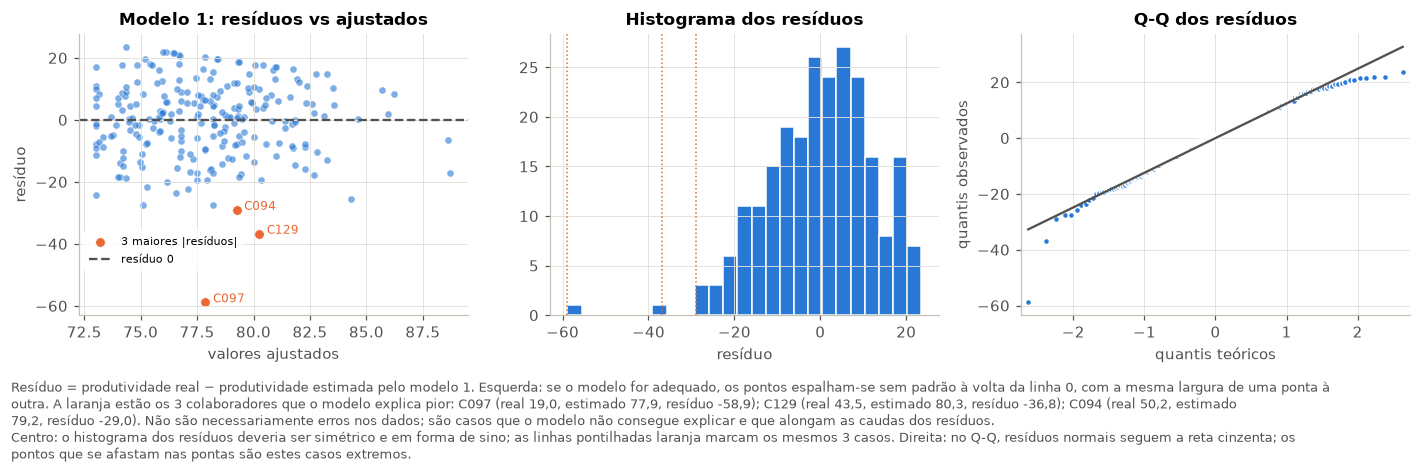

Shapiro-Wilk (normalidade dos resíduos): W = 0.972, p = 0.00013
Breusch-Pagan (variância constante): LM = 0.00, p = 0.976
Durbin-Watson (independência dos resíduos): 1.84  (valores próximos de 2 indicam ausência de autocorrelação)
Distância de Cook: máximo = 0.060 (C134); observações acima de 4/n = 7; acima de 1 = 0
Resíduos: mínimo = -58.9, máximo = 23.5
Observações com maior resíduo em valor absoluto:


,id_colaborador,uso_ia_horas,experiencia_anos,produtividade,ajustado,residuo
96,C097,7.700,7.200,19.000,77.870,-58.870
128,C129,11.500,3.400,43.500,80.250,-36.750
93,C094,9.900,3.100,50.200,79.250,-29.050


In [34]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.6a · Diagnóstico dos resíduos (função usada no M1 e no M2)
# O quê: para um modelo, desenha resíduos vs ajustados, histograma e Q-Q dos resíduos, e calcula:
# - Shapiro-Wilk: os resíduos são normais?
# - Breusch-Pagan: a variância dos resíduos é constante (homocedasticidade)?
# - Durbin-Watson: há autocorrelação? (com dados transversais não testa nada de substantivo,
#   porque depende da ordem das linhas; mostramo-lo por completude, a independência vem do desenho)
# - Distância de Cook: alguma observação domina o ajustamento? (preocupante acima de 1)
# ────────────────────────────────────────────────────────────────────────────────────────
def diagnostico(modelo, dados, nome, ficheiro, k=3):
    res, ajust = modelo.resid, modelo.fittedvalues
    # identifica as observações mais mal explicadas para as assinalar no gráfico
    maiores = res.abs().nlargest(k).index          # as k observações com maior resíduo em valor absoluto
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
    resto = res.index.difference(maiores)
    ax[0].scatter(ajust[resto], res[resto], s=22, color=AZUL, alpha=.6, edgecolor="white", linewidth=.5)
    ax[0].scatter(ajust[maiores], res[maiores], s=40, color=LARANJA, edgecolor="white", linewidth=.5,
                  label=f"{k} maiores |resíduos|")
    ax[0].axhline(0, color=CINZA_TXT, lw=1.5, ls="--", label="resíduo 0")
    for i in maiores:
        ax[0].annotate(dados.loc[i, "id_colaborador"], (ajust.loc[i], res.loc[i]),
                       xytext=(5, 0), textcoords="offset points", fontsize=8, color=LARANJA)
    ax[0].set(title=f"{nome}: resíduos vs ajustados", xlabel="valores ajustados", ylabel="resíduo")
    ax[0].legend(fontsize=7.5, frameon=True, facecolor="white", edgecolor="white", loc="lower left", bbox_to_anchor=(0, 0.14))
    ax[1].hist(res, bins=25, color=AZUL, edgecolor="white")
    for i in maiores:
        ax[1].axvline(res[i], color=LARANJA, lw=1, ls=":")
    ax[1].set(title="Histograma dos resíduos", xlabel="resíduo")
    qq(res, ax[2], "Q-Q dos resíduos")
    plt.tight_layout()
    lista = "; ".join(f"{dados.loc[i, 'id_colaborador']} (real {fpt(dados.loc[i, 'produtividade'])}, estimado "
                      f"{fpt(ajust[i])}, resíduo {fpt(res[i])})" for i in maiores)
    nota(fig, f"Resíduo = produtividade real − produtividade estimada pelo {nome.lower()}. Esquerda: se o modelo for "
              f"adequado, os pontos espalham-se sem padrão à volta da linha 0, com a mesma largura de uma ponta à outra. "
              f"A laranja estão os {k} colaboradores que o modelo explica pior: {lista}. Não são necessariamente erros "
              f"nos dados; são casos que o modelo não consegue explicar e que alongam as caudas dos resíduos.\n"
              f"Centro: o histograma dos resíduos deveria ser simétrico e em forma de sino; as linhas pontilhadas laranja "
              f"marcam os mesmos {k} casos. Direita: no Q-Q, resíduos normais seguem a reta cinzenta; os pontos que se "
              f"afastam nas pontas são estes casos extremos.")
    guardar(fig, ficheiro); plt.show()

    sw = st.shapiro(res)
    bp = het_breuschpagan(res, modelo.model.exog)
    print(f"Shapiro-Wilk (normalidade dos resíduos): W = {sw.statistic:.3f}, p = {sw.pvalue:.2g}")
    print(f"Breusch-Pagan (variância constante): LM = {bp[0]:.2f}, p = {bp[1]:.3f}")
    dw = durbin_watson(res)
    cook = modelo.get_influence().cooks_distance[0]          # mesma ordem das observações do modelo
    mais_influente = dados.loc[res.index[cook.argmax()], "id_colaborador"]
    print(f"Durbin-Watson (independência dos resíduos): {dw:.2f}  (valores próximos de 2 indicam ausência de autocorrelação)")
    print(f"Distância de Cook: máximo = {cook.max():.3f} ({mais_influente}); observações acima de 4/n = {(cook > 4 / len(res)).sum()}; "
          f"acima de 1 = {(cook > 1).sum()}")
    print(f"Resíduos: mínimo = {res.min():.1f}, máximo = {res.max():.1f}")
    print(f"Observações com maior resíduo em valor absoluto:")
    display(dados.loc[maiores, ["id_colaborador", "uso_ia_horas", "experiencia_anos", "produtividade"]]
            .assign(ajustado=ajust.loc[maiores], residuo=res.loc[maiores]).round(2))

diagnostico(m1, d5, "Modelo 1", "fig_5_6_residuos_m1")

In [35]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.6b · Sensibilidade: M1 sem C097
# O quê: volta a estimar o M1 sem C097. Leitura: o declive não muda (0,627), logo C097 não altera
# a conclusão; só afeta a normalidade dos resíduos.
# ────────────────────────────────────────────────────────────────────────────────────────
m1_s = smf.ols("produtividade ~ uso_ia_horas", data=d5[d5.id_colaborador != "C097"]).fit()
print(f"Sem C097: b1 = {m1_s.params['uso_ia_horas']:.3f} (p = {m1_s.pvalues['uso_ia_horas']:.2g}), "
      f"R² = {m1_s.rsquared:.3f}, Shapiro-Wilk dos resíduos p = {st.shapiro(m1_s.resid).pvalue:.3f}")

Sem C097: b1 = 0.627 (p = 9.2e-05), R² = 0.064, Shapiro-Wilk dos resíduos p = 0.030


Verificámos os pressupostos da regressão pela ordem das aulas 4 e 5: primeiro os gráficos, depois os testes.

- **Forma da relação**: no gráfico dos resíduos contra os valores ajustados não há curva nem padrão; os pontos espalham-se à volta de zero.
- **Variância constante**: a dispersão dos resíduos é parecida em toda a largura do gráfico (não há forma de funil) e o teste de Breusch-Pagan não deteta problemas (p = 0,98).
- **Independência**: cada colaborador aparece uma só vez e os dados foram recolhidos num único momento, por isso a independência vem da forma como o estudo foi feito. A estatística de Durbin-Watson (1,84) aparece só por completude: como a docente explica, sem uma ordem no tempo ela é apenas descritiva.
- **Normalidade dos resíduos**: é rejeitada (Shapiro-Wilk p < 0,001). O histograma e o Q-Q mostram uma cauda comprida à esquerda, com o C097 (resíduo −58,9) e o C129 (−36,8), e a ponta direita achatada pelo teto de 98. Sem o C097 o problema diminui muito (p = 0,03) e o declive fica igual (0,63).
- **Observações influentes**: a distância de Cook máxima é 0,06 (C134). Sete observações passam a referência 4/n usada na aula 5 (entre elas C134, C078 e C097), mas nenhuma muda o modelo: retirar o C097 deixa o declive igual (bloco 5.6b, acima).

**O modelo representa bem os dados?** Os pressupostos estão razoavelmente cumpridos, com exceção da normalidade, que se deve sobretudo a um ou dois valores. O problema principal é outro: falta-lhe informação. O R² é só 0,06 e os resíduos vão de −59 a +24 pontos. O bloco 5.6c mostra que os resíduos estão claramente ligados à experiência.

In [36]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 5.6c · Faltam variáveis no modelo simples?
# O quê: correlação entre os resíduos do M1 e variáveis que não entraram no modelo.
# Leitura: correlação de 0,45 com a experiência, sinal de que o M1 omite uma variável importante.
# É a ponte para o capítulo 6.
# ────────────────────────────────────────────────────────────────────────────────────────
# Os resíduos do modelo 1 estão relacionados com variáveis que ficaram de fora?
for v in ["experiencia_anos", "formacao_ia_horas", "complexidade_tarefas", "carga_trabalho_horas"]:
    t = d5.assign(res=m1.resid).dropna(subset=[v])
    r = st.pearsonr(t[v], t.res)
    print(f"cor(resíduo M1, {v:22s}) = {r.statistic:+.3f}  (p = {r.pvalue:.2g})")

cor(resíduo M1, experiencia_anos      ) = +0.451  (p = 3.6e-13)
cor(resíduo M1, formacao_ia_horas     ) = +0.027  (p = 0.68)
cor(resíduo M1, complexidade_tarefas  ) = -0.020  (p = 0.77)
cor(resíduo M1, carga_trabalho_horas  ) = +0.093  (p = 0.16)


A correlação entre os resíduos do modelo simples e a experiência é 0,45 (p < 0,001); com as outras variáveis é praticamente nula. Os colaboradores mais experientes ficam sempre acima do que o modelo prevê, e os menos experientes abaixo. É sinal claro de que o modelo simples deixa de fora uma variável importante: a experiência.

---
## 6. Será que a IA explica tudo?

### 6.1. Outras variáveis candidatas e risco de incluir indicadores de desempenho

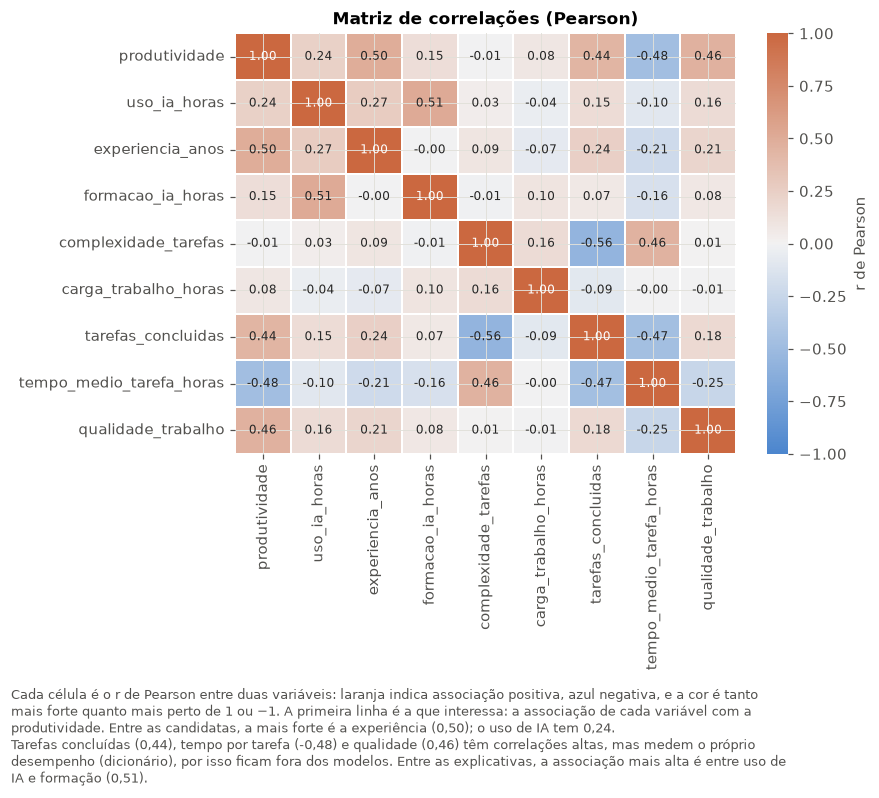

In [37]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 6.1 · Matriz de correlações (candidatas a explicativas)
# O quê: correlações de Pearson entre todas as variáveis quantitativas (Figura 6).
# Uso: escolher variáveis associadas à produtividade, excluindo as que medem o próprio desempenho
# (tarefas concluídas, tempo por tarefa, qualidade), para evitar circularidade.
# ────────────────────────────────────────────────────────────────────────────────────────
vars_num = ["produtividade", "uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas",
            "carga_trabalho_horas", "tarefas_concluidas", "tempo_medio_tarefa_horas", "qualidade_trabalho"]
corr = df[vars_num].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6.3))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 25, s=75, l=55, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=1, linecolor="white", ax=ax,
            cbar_kws={"label": "r de Pearson"}, annot_kws={"size": 8})
ax.set_title("Matriz de correlações (Pearson)")
r_prod = corr["produtividade"]
plt.tight_layout()
nota(fig, f"Cada célula é o r de Pearson entre duas variáveis: laranja indica associação positiva, azul negativa, e a cor "
          f"é tanto mais forte quanto mais perto de 1 ou −1. A primeira linha é a que interessa: a associação de cada "
          f"variável com a produtividade. Entre as candidatas, a mais forte é a experiência ({fpt(r_prod['experiencia_anos'], 2)}); "
          f"o uso de IA tem {fpt(r_prod['uso_ia_horas'], 2)}.\n"
          f"Tarefas concluídas ({fpt(r_prod['tarefas_concluidas'], 2)}), tempo por tarefa ({fpt(r_prod['tempo_medio_tarefa_horas'], 2)}) "
          f"e qualidade ({fpt(r_prod['qualidade_trabalho'], 2)}) têm correlações altas, mas medem o próprio desempenho "
          f"(dicionário), por isso ficam fora dos modelos. Entre as explicativas, a associação mais alta é entre uso de IA "
          f"e formação ({fpt(corr.loc['uso_ia_horas', 'formacao_ia_horas'], 2)}).")
guardar(fig, "fig_6_1_correlacoes"); plt.show()

Variáveis candidatas, a partir da matriz de correlações:

| Variável | r com a produtividade | Papel | Decisão |
|---|---|---|---|
| `experiencia_anos` | 0,50 | Vem antes do desempenho; também ligada ao uso de IA (0,27), logo possível fator de confusão | Incluir |
| `formacao_ia_horas` | 0,15 | Vem antes do desempenho; muito ligada ao uso de IA (0,51) | Incluir |
| `complexidade_tarefas` | −0,01 | Característica do posto de trabalho, referida no enunciado | Incluir (controlo) |
| `carga_trabalho_horas` | 0,08 | Contexto; relação fraca | Teste de robustez |
| `departamento` | ANOVA p = 0,70 | Contexto | Teste de robustez |
| `tarefas_concluidas` | 0,44 | Indicador do mesmo desempenho (dicionário) | Excluir |
| `tempo_medio_tarefa_horas` | −0,48 | Indicador do mesmo desempenho (dicionário) | Excluir |
| `qualidade_trabalho` | 0,46 | Indicador do mesmo desempenho (dicionário) | Excluir |

Tarefas concluídas, tempo por tarefa e qualidade têm correlações altas com a produtividade, mas o dicionário da base avisa que são **indicadores do mesmo desempenho, medidos ao mesmo tempo**. A produtividade não é calculada a partir deles (é uma avaliação global feita por avaliadores), mas mede a mesma coisa vista de outro ângulo. Incluí-los teria três problemas:
1. **Redundância**: estaríamos a explicar o desempenho com outras medidas do próprio desempenho. O R² subia, mas não aprendíamos nada sobre o que leva alguém a ser produtivo.
2. **Esconder o efeito que queremos estudar**: se a IA ajudar a produtividade através de mais tarefas ou de menos tempo por tarefa, pôr essas variáveis no modelo apagaria esse efeito.
3. **Não servem para decidir**: a direção não escolhe à partida quantas tarefas alguém conclui, ao contrário da formação.

Por isso deixámo-los de fora. A carga de trabalho e o departamento têm pouca relação com a produtividade e ficam para um teste de robustez (6.6).

### 6.2. Modelo múltiplo

In [38]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 6.2 · Regressão linear múltipla (modelo M2)
# O quê: produtividade em função do uso de IA + experiência + formação em IA + complexidade,
# com os 233 colaboradores que têm as 5 variáveis.
# Porquê estas: são anteriores ao desempenho, são as apontadas no enunciado e a experiência e a
# formação estão ligadas ao uso de IA e à produtividade (potenciais fatores de confusão).
# ────────────────────────────────────────────────────────────────────────────────────────
vars_m2 = ["produtividade", "uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas"]
d6 = df.dropna(subset=vars_m2).copy()
print("n (casos completos) =", len(d6))
m2 = smf.ols("produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas + complexidade_tarefas",
             data=d6).fit()
print(m2.summary(slim=True))

n (casos completos) = 233
                            OLS Regression Results                            
Dep. Variable:          produtividade   R-squared:                       0.280
Model:                            OLS   Adj. R-squared:                  0.267
No. Observations:                 233   F-statistic:                     22.14
Covariance Type:            nonrobust   Prob (F-statistic):           1.85e-15
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               67.3227      2.604     25.857      0.000      62.192      72.453
uso_ia_horas             0.1293      0.179      0.722      0.471      -0.224       0.482
experiencia_anos         1.5838      0.190      8.316      0.000       1.209       1.959
formacao_ia_horas        0.2308      0.122      1.896      0.059      -0.009       0.471
complexidade_tarefas    -0.6613      0.716   

Para além do uso de IA, o modelo tem três variáveis, escolhidas porque:
1. **vêm antes do desempenho** e não são medidas do próprio desempenho (evita o problema de 6.1);
2. **são os fatores que o enunciado aponta** como possíveis influências: experiência, formação e complexidade das tarefas;
3. a experiência e a formação estão ligadas **ao mesmo tempo** ao uso de IA e à produtividade. São, por isso, as candidatas naturais a fatores de confusão: se as deixássemos de fora, o coeficiente da IA ficaria com mérito que não é dele.

Modelo: produtividade = β₀ + β₁·uso_IA + β₂·experiência + β₃·formação_IA + β₄·complexidade + ε, estimado por mínimos quadrados com **n = 233** colaboradores com dados completos. O teste F global mostra que o modelo, no seu conjunto, explica parte da produtividade (F(4, 228) = 22,1; p < 0,001).

### 6.3. Equação e interpretação do coeficiente da IA

In [39]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 6.3 · Coeficientes do modelo M2
# O quê: tabela de coeficientes com erro-padrão, t, valor-p e IC 95% de cada variável.
# Leitura: só a experiência é claramente significativa; o coeficiente da IA (0,13) não é.
# Não comparamos a importância das variáveis pelo tamanho dos coeficientes, porque estão em
# unidades diferentes (aula 5).
# ────────────────────────────────────────────────────────────────────────────────────────
coef = pd.DataFrame({"coef": m2.params, "erro-padrão": m2.bse, "t": m2.tvalues, "p": m2.pvalues,
                     "IC95% inf": m2.conf_int()[0], "IC95% sup": m2.conf_int()[1]})
display(coef.round(4))

,coef,erro-padrão,t,p,IC95% inf,IC95% sup
Intercept,67.323,2.604,25.857,0.000,62.192,72.453
uso_ia_horas,0.129,0.179,0.722,0.471,-0.224,0.482
experiencia_anos,1.584,0.190,8.316,0.000,1.209,1.959
formacao_ia_horas,0.231,0.122,1.896,0.059,-0.009,0.471
complexidade_tarefas,-0.661,0.716,-0.923,0.357,-2.073,0.750


$$\widehat{\text{produtividade}} = 67{,}32 + 0{,}129\,\text{uso\_IA} + 1{,}584\,\text{experiência} + 0{,}231\,\text{formação\_IA} - 0{,}661\,\text{complexidade}$$

**Coeficiente do uso de IA (0,129; IC 95%: −0,22 a 0,48; p = 0,47).** Comparando colaboradores com a mesma experiência, a mesma formação em IA e a mesma complexidade de tarefas, cada hora semanal a mais de IA corresponde a uma produtividade média só 0,13 pontos mais alta, um valor pequeno e não significativo. O intervalo de confiança inclui o zero e até valores negativos: depois de ter em conta os outros fatores, os dados são compatíveis com a IA não ter qualquer associação com a produtividade.

Restantes coeficientes (sempre «mantendo o resto igual»):
- **Experiência** (1,58; p < 0,001): cada ano a mais de experiência corresponde a mais 1,6 pontos de produtividade. É a única variável claramente significativa.
- **Formação em IA** (0,23; p = 0,059): relação positiva, mesmo à beira da significância; 10 h de formação correspondem a cerca de 2,3 pontos.
- **Complexidade** (−0,66; p = 0,36): sem relação significativa.
- **Ordenada na origem** (67,3): corresponde a 0 anos de experiência, 0 h de IA, 0 h de formação e complexidade 0. Como a complexidade mínima é 1, esta combinação não existe e o valor não tem leitura prática.

Não ordenamos as variáveis por importância pelo tamanho dos coeficientes, porque estão em unidades diferentes (anos, horas por semana, horas de formação, níveis de 1 a 5), como a docente alerta na aula 5. O que podemos dizer é que a experiência é a única com uma relação clara com a produtividade.

### 6.4. Alteração do coeficiente da IA

,b_IA,IC inf,IC sup,p,R² aj.
M1: só IA,0.639,0.313,0.965,0.000,0.056
+ formação,0.597,0.216,0.977,0.002,0.053
+ experiência,0.309,0.009,0.610,0.044,0.259
+ experiência + formação,0.128,-0.225,0.481,0.476,0.268
M2: + complexidade,0.129,-0.224,0.482,0.471,0.267


Redução do coeficiente da IA: 80%


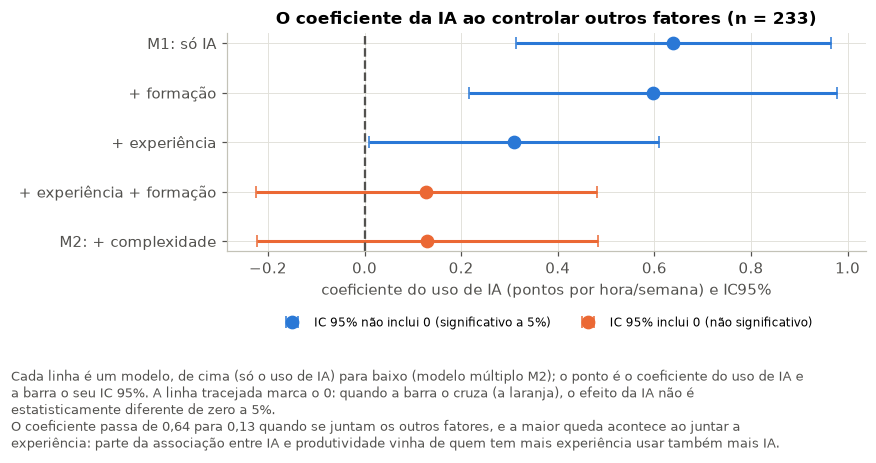

In [40]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 6.4 · Como muda o coeficiente da IA ao acrescentar controlos
# O quê: reestima o M1 com os mesmos 233 casos e acrescenta as variáveis uma a uma, registando o
# coeficiente da IA e o seu IC (Figura 7).
# Leitura: só com a experiência o coeficiente cai para metade; com tudo cai 80% (0,64 → 0,13).
# É o efeito de uma variável omitida (fator de confusão), o «paradoxo» do título.
# ────────────────────────────────────────────────────────────────────────────────────────
m1_233 = smf.ols("produtividade ~ uso_ia_horas", data=d6).fit()   # modelo 1 com os mesmos 233 casos
# sequência de modelos encaixados: cada um acrescenta variáveis ao anterior
passos = {
    "M1: só IA": "produtividade ~ uso_ia_horas",
    "+ formação": "produtividade ~ uso_ia_horas + formacao_ia_horas",
    "+ experiência": "produtividade ~ uso_ia_horas + experiencia_anos",
    "+ experiência + formação": "produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas",
    "M2: + complexidade": "produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas + complexidade_tarefas",
}
evol = pd.DataFrame({k: (lambda f: pd.Series({"b_IA": f.params["uso_ia_horas"],
                                               "IC inf": f.conf_int().loc["uso_ia_horas", 0],
                                               "IC sup": f.conf_int().loc["uso_ia_horas", 1],
                                               "p": f.pvalues["uso_ia_horas"], "R² aj.": f.rsquared_adj}))
                     (smf.ols(v, d6).fit()) for k, v in passos.items()}).T
display(evol.round(3))
print(f"Redução do coeficiente da IA: {100 * (1 - m2.params['uso_ia_horas'] / m1_233.params['uso_ia_horas']):.0f}%")

fig, ax = plt.subplots(figsize=(8, 3.4))
yy = np.arange(len(evol))[::-1]
inclui_0 = ((evol["IC inf"] <= 0) & (evol["IC sup"] >= 0)).values
for cor, sel, rot in [(AZUL, ~inclui_0, "IC 95% não inclui 0 (significativo a 5%)"),
                      (LARANJA, inclui_0, "IC 95% inclui 0 (não significativo)")]:
    e = evol[sel]
    if len(e):
        ax.errorbar(e["b_IA"], yy[sel], xerr=[e["b_IA"] - e["IC inf"], e["IC sup"] - e["b_IA"]],
                    fmt="o", color=cor, ecolor=cor, capsize=4, markersize=8, lw=2, label=rot)
ax.axvline(0, color=CINZA_TXT, lw=1.5, ls="--")
ax.set_yticks(yy, evol.index); ax.set_xlabel("coeficiente do uso de IA (pontos por hora/semana) e IC95%")
ax.set_title("O coeficiente da IA ao controlar outros fatores (n = 233)")
ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.tight_layout()
nota(fig, f"Cada linha é um modelo, de cima (só o uso de IA) para baixo (modelo múltiplo M2); o ponto é o coeficiente do "
          f"uso de IA e a barra o seu IC 95%. A linha tracejada marca o 0: quando a barra o cruza (a laranja), o efeito "
          f"da IA não é estatisticamente diferente de zero a 5%.\n"
          f"O coeficiente passa de {fpt(evol['b_IA'].iloc[0], 2)} para {fpt(evol['b_IA'].iloc[-1], 2)} quando se juntam os "
          f"outros fatores, e a maior queda acontece ao juntar a experiência: parte da associação entre IA e produtividade "
          f"vinha de quem tem mais experiência usar também mais IA.")
guardar(fig, "fig_6_4_coeficiente_ia"); plt.show()

O coeficiente da IA passa de **0,639** (modelo simples, com os mesmos 233 casos; p < 0,001) para **0,129** (modelo múltiplo; p = 0,47). Desce cerca de 80% e deixa de ser significativo.

A tabela e a figura mostram que variável «rouba» a associação. Juntar só a formação quase não mexe no coeficiente (0,60). Juntar a experiência corta-o para metade (0,31; p = 0,04). Com experiência e formação juntas, cai para 0,13. A explicação está nas correlações de 6.1: quem tem mais experiência e mais formação usa mais IA (r = 0,27 e 0,51) e a experiência está muito ligada à produtividade (r = 0,50). Ou seja, quem usa mais IA é mais produtivo sobretudo **porque é mais experiente**, e não por usar mais IA. A experiência é o fator de confusão de que suspeitávamos em 3.4, e é este o «paradoxo» do título.

Uma ressalva: se a formação levar a usar mais IA e isso levar a mais produtividade, ao controlar a formação podemos estar a tirar à IA parte de um efeito real. Mesmo assim, controlando só a experiência, que não é consequência de usar IA, o coeficiente já cai para metade.

### 6.5. Comparação da capacidade explicativa

In [41]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 6.5 · Comparar a capacidade explicativa (R², R² ajustado, teste F parcial)
# O quê: compara M1 e M2 com as MESMAS 233 observações (senão os R² não são comparáveis).
# Porquê R² ajustado: o R² sobe sempre que se juntam variáveis; o ajustado desconta-as.
# Porquê teste F parcial (aula 4, compare_f_test): testa se as 3 variáveis acrescentadas, em
# conjunto, melhoram o modelo.
# ────────────────────────────────────────────────────────────────────────────────────────
comp = pd.DataFrame({
    "M1 (só IA)": [m1_233.nobs, m1_233.df_model, m1_233.rsquared, m1_233.rsquared_adj, m1_233.fvalue, m1_233.f_pvalue],
    "M2 (IA + 3 variáveis)": [m2.nobs, m2.df_model, m2.rsquared, m2.rsquared_adj, m2.fvalue, m2.f_pvalue],
}, index=["n", "nº preditores", "R²", "R² ajustado", "F global", "p (F global)"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(comp)

# Teste F parcial (aula 4): as três variáveis acrescentadas melhoram o modelo? Mesmos 233 casos.
f_parc, p_parc, gl_parc = m2.compare_f_test(m1_233)
print(f"Teste F parcial: F({int(gl_parc)}, {int(m2.df_resid)}) = {f_parc:.2f}, p = {p_parc:.2g}")
print(f"Soma dos quadrados dos resíduos: M1 = {m1_233.ssr:,.0f} | M2 = {m2.ssr:,.0f}")

,M1 (só IA),M2 (IA + 3 variáveis)
n,233.0000,233.0000
nº preditores,1.0000,4.0000
R²,0.0605,0.2798
R² ajustado,0.0565,0.2672
F global,14.8822,22.1441
p (F global),0.0001,0.0000


Teste F parcial: F(3, 228) = 23.14, p = 4.1e-13
Soma dos quadrados dos resíduos: M1 = 35,990 | M2 = 27,590


A comparação é feita com os mesmos 233 colaboradores (voltámos a estimar o modelo simples só com eles), porque comparar modelos com casos diferentes não seria justo. É uma regra das aulas.

O R² sobe de 0,061 para 0,280. Mas o R² sobe sempre que se juntam variáveis, mesmo inúteis, por isso olhamos para o **R² ajustado**, que desconta o número de variáveis: passa de **0,056 para 0,267**, quase cinco vezes mais. Com 233 pessoas para 4 variáveis (cerca de 58 por variável), o ganho não vem de termos complicado o modelo.

O **teste F parcial** (aula 4) responde diretamente à pergunta «as três variáveis juntas melhoram o modelo?»: a soma dos quadrados dos resíduos (o erro que fica por explicar) desce de 35 990 para 27 590 e F(3, 228) = 23,1 (p < 0,001). Uma melhoria deste tamanho não se explica pelo acaso.

Portanto, sim: o modelo com mais variáveis é claramente melhor. Mesmo assim, pelo R² ajustado, cerca de 73% da variação da produtividade continua por explicar (pelo R², 72%).

### 6.6. Associação entre variáveis explicativas e comportamento dos resíduos

Correlações entre as variáveis explicativas:


,uso_ia_horas,experiencia_anos,formacao_ia_horas,complexidade_tarefas
uso_ia_horas,1.000,0.270,0.510,0.030
experiencia_anos,0.270,1.000,-0.000,0.100
formacao_ia_horas,0.510,-0.000,1.000,-0.010
complexidade_tarefas,0.030,0.100,-0.010,1.000


,Variável,VIF
1,uso_ia_horas,1.510
2,experiencia_anos,1.120
3,formacao_ia_horas,1.400
4,complexidade_tarefas,1.010


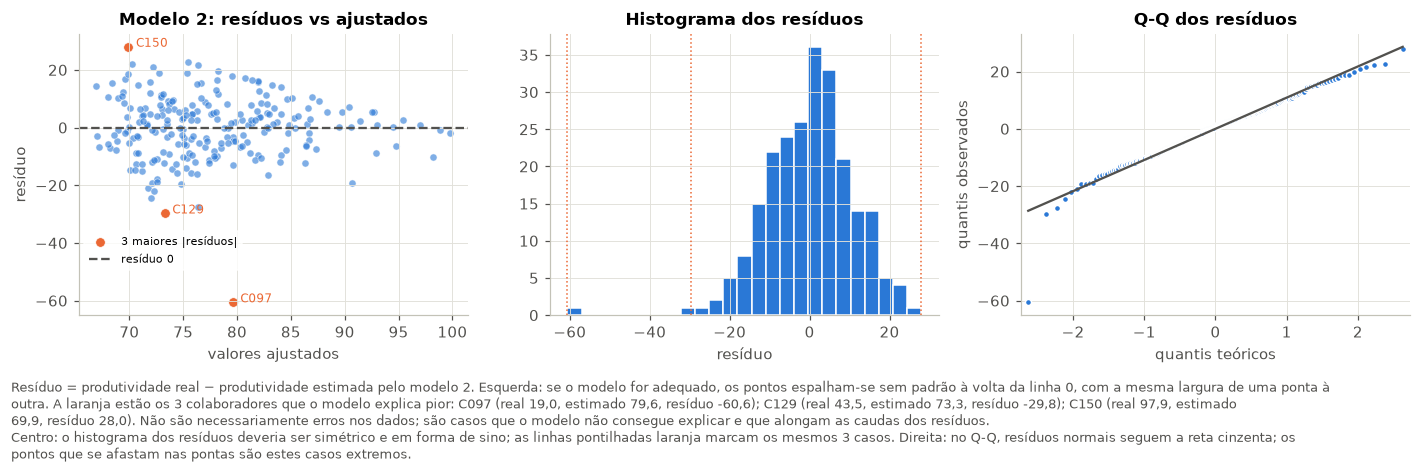

Shapiro-Wilk (normalidade dos resíduos): W = 0.966, p = 2.1e-05
Breusch-Pagan (variância constante): LM = 6.19, p = 0.185
Durbin-Watson (independência dos resíduos): 1.95  (valores próximos de 2 indicam ausência de autocorrelação)
Distância de Cook: máximo = 0.066 (C097); observações acima de 4/n = 7; acima de 1 = 0
Resíduos: mínimo = -60.6, máximo = 28.0
Observações com maior resíduo em valor absoluto:


,id_colaborador,uso_ia_horas,experiencia_anos,produtividade,ajustado,residuo
96,C097,7.700,7.200,19.000,79.600,-60.600
128,C129,11.500,3.400,43.500,73.290,-29.790
149,C150,2.100,1.600,97.900,69.910,27.990


In [42]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 6.6a · Multicolinearidade e resíduos do M2
# O quê: correlações entre explicativas e VIF (fator de inflação da variância; problemático acima
# de 5); depois o mesmo diagnóstico de resíduos do bloco 5.6a, agora para o M2.
# Leitura: VIF máximo 1,51, sem multicolinearidade; a normalidade falha só por causa de C097.
# ────────────────────────────────────────────────────────────────────────────────────────
preditores = ["uso_ia_horas", "experiencia_anos", "formacao_ia_horas", "complexidade_tarefas"]
print("Correlações entre as variáveis explicativas:")
display(d6[preditores].corr().round(2))
X = m2.model.exog
vif = pd.DataFrame({"Variável": m2.model.exog_names,
                    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]})
display(vif.loc[vif["Variável"] != "Intercept"].round(2))
diagnostico(m2, d6, "Modelo 2", "fig_6_6_residuos_m2")

In [43]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 6.6b · Robustez das opções tomadas
# O quê: reestima o M2 (a) sem C097, (b) com carga de trabalho e departamento, (c) com a
# complexidade como categórica, e testa se (c) melhora o modelo (teste F); (d) testa se a
# associação da IA depende da experiência (termo de interação IA × experiência).
# Leitura: o coeficiente da IA fica sempre entre 0,12 e 0,15 e nunca é significativo.
# ────────────────────────────────────────────────────────────────────────────────────────
m2_s = smf.ols(m2.model.formula, d6[d6.id_colaborador != "C097"]).fit()
m2_ext = smf.ols(m2.model.formula + " + carga_trabalho_horas + C(departamento)", d6).fit()
m2_cat = smf.ols("produtividade ~ uso_ia_horas + experiencia_anos + formacao_ia_horas + C(complexidade_tarefas)", d6).fit()  # (c) complexidade como categórica
# (d) a associação da IA depende da experiência? termo de interação IA × experiência
m2_int = smf.ols(m2.model.formula + " + uso_ia_horas:experiencia_anos", d6).fit()
rob = pd.DataFrame({
    "M2": [m2.params["uso_ia_horas"], m2.pvalues["uso_ia_horas"], m2.rsquared_adj],
    "M2 sem C097": [m2_s.params["uso_ia_horas"], m2_s.pvalues["uso_ia_horas"], m2_s.rsquared_adj],
    "M2 + carga + departamento": [m2_ext.params["uso_ia_horas"], m2_ext.pvalues["uso_ia_horas"], m2_ext.rsquared_adj],
    "M2 com complexidade categórica": [m2_cat.params["uso_ia_horas"], m2_cat.pvalues["uso_ia_horas"], m2_cat.rsquared_adj],
}, index=["b_IA", "p (IA)", "R² aj."]).T
display(rob.round(3))
print(f"Sem C097: Shapiro-Wilk dos resíduos p = {st.shapiro(m2_s.resid).pvalue:.3f}")
print(f"Interação IA × experiência: coef = {m2_int.params['uso_ia_horas:experiencia_anos']:.3f}, "
      f"p = {m2_int.pvalues['uso_ia_horas:experiencia_anos']:.3f}")
f_cat = sm.stats.anova_lm(m2, m2_cat)
print(f"Complexidade categórica vs numérica: F({int(f_cat['df_diff'].iloc[1])}, {int(f_cat['df_resid'].iloc[1])}) = {f_cat['F'].iloc[1]:.2f}, p = {f_cat['Pr(>F)'].iloc[1]:.3f}")


,b_IA,p (IA),R² aj.
M2,0.129,0.471,0.267
M2 sem C097,0.146,0.384,0.302
M2 + carga + departamento,0.144,0.446,0.274
M2 com complexidade categórica,0.122,0.500,0.272


Sem C097: Shapiro-Wilk dos resíduos p = 0.965
Interação IA × experiência: coef = 0.028, p = 0.499
Complexidade categórica vs numérica: F(3, 225) = 1.55, p = 0.203


**Relação entre as variáveis explicativas.** A correlação mais alta é entre uso de IA e formação (0,51), moderada; as outras são fracas. Todos os VIF estão abaixo de 1,6 (o maior é 1,51, no uso de IA) e, na referência da docente, valores entre 1 e 5 não preocupam. Não há multicolinearidade (variáveis explicativas que dizem quase o mesmo): o erro-padrão do coeficiente da IA quase não muda do modelo simples (0,166, com os mesmos 233 casos) para o múltiplo (0,179). A IA perde significância porque o modelo passa a ter em conta a experiência, não por colinearidade.

**Resíduos do modelo 2.**
- Forma da relação: sem curva nem padrão nos resíduos contra os valores ajustados.
- Variância constante: sem forma de funil; Breusch-Pagan p = 0,19, não rejeitada.
- Independência: vem do desenho do estudo, como no modelo 1 (o Durbin-Watson, 1,95, é só descritivo).
- Normalidade: rejeitada (Shapiro-Wilk p < 0,001), mas quase só por causa do C097, com um resíduo de −60,6, muito longe dos outros. Sem ele, os resíduos são compatíveis com a normalidade (p = 0,97) e o coeficiente da IA quase não muda (0,146; p = 0,38).
- Observações influentes: distância de Cook máxima 0,07 (C097); sete observações passam a referência 4/n (C097, C134 e C129 entre elas), mas nenhuma muda as conclusões, como mostra a tabela de robustez.

**Robustez das nossas escolhas** (bloco 6.6b). Testámos se a conclusão sobre a IA depende de decisões que tomámos:
- sem o C097: 0,146 (p = 0,38);
- juntando a carga de trabalho e o departamento: 0,144 (p = 0,45);
- com a complexidade tratada como categoria em vez de número: 0,122 (p = 0,50), e o modelo não melhora (F(3, 225) = 1,55; p = 0,20), o que justifica a simplificação de 1.4;
- deixando a relação da IA variar com a experiência (interação IA × experiência): o termo é praticamente nulo (0,028; p = 0,50). A IA não está mais associada à produtividade nos experientes do que nos inexperientes, nem o contrário.

Em todas as versões o coeficiente da IA fica entre 0,12 e 0,15 e nunca é significativo. O modelo 2 cumpre razoavelmente os pressupostos e a conclusão não depende das nossas escolhas.

### 6.7. Modelo mais adequado

Escolhemos o **modelo 2 (múltiplo)** para responder à questão de investigação:
1. A questão pergunta como muda a relação quando se têm em conta outros fatores, e só o modelo múltiplo responde a isso.
2. Explica quase cinco vezes mais (R² ajustado 0,27 contra 0,06), com os mesmos colaboradores, e o teste F parcial confirma a melhoria.
3. O modelo simples dá à IA um mérito que é, em grande parte, da experiência: vimos em 5.6 que os seus resíduos têm correlação 0,45 com a experiência.
4. É simples (4 variáveis, VIF baixos), só usa fatores que vêm antes do desempenho e cumpre razoavelmente os pressupostos.

O modelo 1 continua útil para descrever a relação «em bruto», mas não para a explicar.

---
## 7. Conclusão da investigação

In [44]:
# ────────────────────────────────────────────────────────────────────────────────────────
# BLOCO 7 · Síntese dos resultados principais
# O quê: reúne numa tabela os números que sustentam as conclusões do capítulo 7.
# ────────────────────────────────────────────────────────────────────────────────────────
sintese = pd.DataFrame({
    "Resultado": ["Correlação IA–produtividade (Pearson, n = 236)", "b_IA no modelo simples (n = 233)",
                  "b_IA no modelo múltiplo (n = 233)", "R² aj. modelo simples", "R² aj. modelo múltiplo",
                  "ANOVA departamentos (p)"],
    "Valor": [f"r = {fpt(r_p.statistic, 2)} (p < 0,001)",
              f"{fpt(m1_233.params['uso_ia_horas'], 3)} (p < 0,001)",
              f"{fpt(m2.params['uso_ia_horas'], 3)} (p = {fpt(m2.pvalues['uso_ia_horas'], 2)})",
              fpt(m1_233.rsquared_adj, 3), fpt(m2.rsquared_adj, 3), fpt(anova.pvalue, 2)],
})
display(sintese)

,Resultado,Valor
0,"Correlação IA–produtividade (Pearson, n = 236)","r = 0,24 (p < 0,001)"
1,b_IA no modelo simples (n = 233),"0,639 (p < 0,001)"
2,b_IA no modelo múltiplo (n = 233),"0,129 (p = 0,47)"
3,R² aj. modelo simples,"0,056"
4,R² aj. modelo múltiplo,"0,267"
5,ANOVA departamentos (p),"0,70"


### 7.1. Quem usa mais IA é mais produtivo?
Em média, sim, mas pouco. A associação é positiva, fraca e estatisticamente significativa (r = 0,24; ρ = 0,27; p < 0,001): no quarto de colaboradores que mais usa IA a produtividade mediana é 84,9, contra 73,0 no quarto que menos usa. Mas o uso de IA só explica cerca de 6% da variação e há muitos contraexemplos (o C134, com 25 h, tem 71,6; o C014, com 4,9 h, tem 98). A ideia da direção é verdadeira como tendência média, mas errada como regra para cada pessoa.

### 7.2. A relação mantém-se quando se consideram outros fatores?
Não. Quando comparamos colaboradores com a mesma experiência, formação em IA e complexidade de tarefas, o coeficiente da IA cai cerca de 80% (de 0,64 para 0,13) e deixa de ser significativo (p = 0,47; IC 95%: −0,22 a 0,48). O fator mais ligado à produtividade é a experiência (mais 1,6 pontos por ano; p < 0,001). O resultado mantém-se sem o C097, juntando a carga de trabalho e o departamento, e com a complexidade tratada como categoria.

### 7.3. Resultado mais inesperado
O mais inesperado foi a associação da IA quase desaparecer quando se tem em conta a experiência, apesar de ser claramente significativa sozinha. A prova: o coeficiente da IA é 0,639 (p < 0,001) no modelo simples e 0,129 (p = 0,47) no múltiplo, com os mesmos 233 colaboradores, e os VIF baixos (< 1,6) mostram que isto não é um problema de colinearidade. A associação inicial era, em grande parte, a experiência «disfarçada»: os mais experientes usam mais IA (r = 0,27) e são mais produtivos (r = 0,50). Também nos surpreendeu que quem mais usa IA (C134) esteja abaixo da média e que os departamentos não difiram (p = 0,70), apesar de Desenvolvimento usar claramente mais IA.

### 7.4. Limitações
1. **Tipo de estudo.** Há uma única medição, sem distribuição ao acaso do uso de IA. Não permite falar de causa nem excluir que a relação vá no sentido contrário, ou que se deva a fatores que não foram medidos (motivação, competência digital, tipo de tarefa, qualidade da ferramenta).
2. **Qualidade e medição dos dados.** Os dados são sintéticos. A produtividade é uma avaliação feita por avaliadores, com um teto em 98 (13 colaboradores) que impede distinguir os melhores; há um valor suspeito (C097 = 19); e o uso de IA mede quantidade (horas), não se a IA é bem usada.

Além disso, o modelo final deixa cerca de 73% da variação por explicar (pelo R² ajustado) e a complexidade, que é ordinal, foi tratada como número (vimos em 6.6 que isso não muda as conclusões).

### 7.5. Recomendação: tornar obrigatória a utilização de IA?
Não recomendaríamos tornar a IA obrigatória com base nestes resultados.
- **Associação não é causa.** A associação «em bruto» é fraca e desaparece quando comparamos pessoas com a mesma experiência e formação. Não há evidência de que mais horas de IA tragam mais produtividade.
- **O ganho seria pequeno.** Mesmo no cenário mais favorável (o modelo simples), seriam cerca de 0,6 pontos por hora: impor mais 5 h por semana daria, no máximo, uns 3 pontos, com custos (tempo, licenças, resistência à mudança) que não avaliámos.
- **Uma regra igual para todos ignora as diferenças.** A experiência é o que mais pesa, a formação em IA mostra uma relação positiva (p ≈ 0,06), e o benefício da IA pode depender do tipo de tarefa e de quem a usa.

Em alternativa, sugerimos: manter a IA disponível mas opcional; investir em boa formação; para saber se a IA causa mais produtividade, fazer um estudo piloto controlado (por exemplo, dar acesso e formação a equipas escolhidas ao acaso e medir a produtividade antes e depois); e melhorar a medição, com uma escala de produtividade sem teto e registo de como a IA é usada.

**Resposta à questão central:** nestes dados, quem usa mais IA é um pouco mais produtivo, mas essa vantagem explica-se sobretudo por serem colaboradores mais experientes e formados. Trabalhar com IA não significa, por si só, trabalhar melhor.

### Síntese por nível de análise

Como pede a nota final do enunciado, separamos o que é observação descritiva, resultado inferencial, explicação estatística e recomendação:

| Nível | O que concluímos |
|---|---|
| **Descritivo** (cap. 1 a 3) | Produtividade média 78,0 (mediana 79,4); uso de IA médio 7,7 h por semana. Quem usa mais IA tende a ser um pouco mais produtivo (mediana 73,0 no quarto que menos usa contra 84,9 no que mais usa), mas com muitas exceções. Os departamentos têm produtividades parecidas; Desenvolvimento usa mais IA sem ser o mais produtivo. |
| **Inferencial** (cap. 3 e 4) | Associação positiva, fraca e significativa (r = 0,24; p < 0,001). Sem evidência de diferenças entre departamentos (ANOVA p = 0,70; Welch p = 0,68; Kruskal-Wallis p = 0,71). Produtividade média: IC 95% [76,4 ; 79,7]. |
| **Explicação estatística** (cap. 5 e 6) | No modelo simples, +0,63 pontos por hora de IA (R² ajustado 0,06). Com a experiência, a formação e a complexidade no modelo, o coeficiente da IA cai cerca de 80% e deixa de ser significativo (0,13; p = 0,47); a experiência é o principal fator (+1,6 pontos por ano). O modelo múltiplo explica 27% da variação (R² ajustado; R² = 0,28) e a melhoria é significativa (teste F parcial, p < 0,001). |
| **Recomendação** (7.5) | Não tornar a IA obrigatória: mantê-la opcional, investir em formação e avaliar o efeito com um estudo piloto controlado, melhorando a medição da produtividade e do uso de IA. |

---
### Referências
- Coelho, L. (2026). *Modelos Estatísticos para Inteligência Artificial*: aulas 1 a 8, guiões de código e infográficos de testes estatísticos (material de apoio da UC). Mestrado em Inteligência Artificial, IPCA.
- Montgomery, D. C., Peck, E. A., & Vining, G. G. (2021). *Introduction to Linear Regression Analysis* (6.ª ed.). Wiley.
- Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proc. 9th Python in Science Conference*.
- Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.